# Étude de cas 1 : Lecture automatique des chèques
## Jalon 2 : Voir les chiffres (CNN, détecteur d'altération, auto-encodeur)

**M2 SDIA - Advanced Artificial Intelligence, 2026-2027**
**Auteurs : Hanane Ait Lhaj - Hafssa Miftah Idrissi - Fatimazahra Lasfar**

**Objectif.** Remplacer le MLP du jalon 1 par un réseau convolutif qui lit le montant par positions, construire un détecteur de chèques altérés, puis un auto-encodeur qui nettoie les images du nouveau scanner (B) avant lecture.

| # | Section |
|---|---|
| 1 | Environnement, graine, versions |
| 2 | Données : scanners A et B, types d'altération |
| 3 | Fonctions utilitaires |
| 4 | MLP de référence |
| 5 | Vérification théorique : dimensions, paramètres, champ réceptif |
| 6 | Étude de conception du CNN |
| 7 | CNN final et comparaison au MLP |
| 8 | Détecteur d'altération |
| 9 | Scanner B, corruption et auto-encodeur débruiteur |
| 10 | Évaluation finale sur le test |
| 11 | Problèmes rencontrés et améliorations |
| 12 | Page de décisions |
| 13 | Fichiers produits |

**Protocole.** Tous les réglages se font sur la validation. Le test n'est utilisé qu'une fois, à la section 10, sur les modèles figés. Graine fixée (`SEED = 0`), versions affichées en section 1, toutes les expériences sont écrites dans `journal.jsonl` avec `jalon=2`, essais infructueux compris.

**Fonctionnement.** Les données, les modèles et le journal sont dans le dossier `uc1_jalon2` de Google Drive. Chaque cellule d'entraînement recharge le modèle enregistré s'il existe et ne le ré-entraîne que s'il est absent : le notebook s'exécute donc en quelques minutes. Les journaux d'entraînement affichés sont ceux de l'exécution d'origine. Pour tout ré-entraîner, il suffit de supprimer les fichiers `.keras` du dossier.

## 1. Environnement, graine, versions

Le dossier de travail est monté depuis Drive. La graine fixe les poids initiaux, le dropout, le mélange des données et les décalages aléatoires.

In [1]:
import os
from google.colab import drive
drive.mount("/content/drive")
DOSSIER = "/content/drive/MyDrive/uc1_jalon2"
os.makedirs(DOSSIER, exist_ok=True)
os.chdir(DOSSIER)
print("dossier de travail :", os.getcwd())
print(os.listdir("."))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dossier de travail : /content/drive/MyDrive/uc1_jalon2
['uc1_domaineA.npz', 'uc1_domaineB.npz', 'journal.jsonl', 'resultats_design.json', 'cnn_final_80ep.keras', 'mlp_base_80ep.keras', 'detecteur_blocs4.keras', 'histories_jalon2.json', 'notes_jalon2.json']


In [2]:
import random, platform, json, time, os
import numpy as np, tensorflow as tf, sklearn
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
from IPython.display import display
from scipy.ndimage import gaussian_filter, rotate
from sklearn.metrics import roc_auc_score, roc_curve

SEED = 0
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

L_MAX = 5
N_CLASSES = 11
EMPTY = 10
IMG_H, IMG_W = 32, 128
NOMS_POS = ["unités", "dizaines", "centaines", "milliers", "dizaines de milliers"]

print("Python", platform.python_version(), "| TensorFlow", tf.__version__,
      "| scikit-learn", sklearn.__version__, "| NumPy", np.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

Python 3.13.15 | TensorFlow 2.21.0 | scikit-learn 1.6.1 | NumPy 2.1.3
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Données : scanners A et B

Le scanner A (référence) fournit 15 000 / 3 000 / 5 000 images d'entraînement, de validation et de test. Le scanner B (nouveau) en fournit 600 / 400 / 3 000, avec les mêmes clés : image 32 × 128, montant écrit, indicateur d'altération, type d'altération.

Les pixels sont ramenés dans [0, 1] et on ajoute un axe canal : les images ont la forme `(N, 32, 128, 1)`, attendue par les convolutions. Le CNN et le détecteur sont entraînés sur A. Les images de B ne servent qu'à évaluer le débruitage (section 9).

In [3]:
if not (os.path.exists("uc1_domaineA.npz") and os.path.exists("uc1_domaineB.npz")):
    from google.colab import files
    files.upload()

SPLITS = ["train", "val", "test"]

def charger(chemin):
    d = np.load(chemin, allow_pickle=True)
    print(chemin, "clés :", d.files)
    X = {s: (d[f"X_{s}"].astype("float32") / 255.0)[..., None] for s in SPLITS}
    M = {}
    for s in SPLITS:
        M[f"montant_{s}"] = d[f"montant_{s}"].astype(str)
        if f"altere_{s}" in d.files:
            M[f"altere_{s}"] = d[f"altere_{s}"]
        if f"type_alteration_{s}" in d.files:
            M[f"type_{s}"] = d[f"type_alteration_{s}"]
    return X, M

XA, A = charger("uc1_domaineA.npz")
XB, B = charger("uc1_domaineB.npz")

for nom, X in [("A", XA), ("B", XB)]:
    for s in SPLITS:
        print(f"{nom} {s:5s}", X[s].shape, f"min/max = {X[s].min():.2f}/{X[s].max():.2f}")
print("exemples A :", A["montant_val"][:5], "| exemples B :", B["montant_val"][:5])

uc1_domaineA.npz clés : ['X_train', 'montant_train', 'altere_train', 'type_alteration_train', 'X_val', 'montant_val', 'altere_val', 'type_alteration_val', 'X_test', 'montant_test', 'altere_test', 'type_alteration_test']
uc1_domaineB.npz clés : ['X_train', 'montant_train', 'altere_train', 'type_alteration_train', 'X_val', 'montant_val', 'altere_val', 'type_alteration_val', 'X_test', 'montant_test', 'altere_test', 'type_alteration_test']
A train (15000, 32, 128, 1) min/max = 0.00/1.00
A val   (3000, 32, 128, 1) min/max = 0.00/1.00
A test  (5000, 32, 128, 1) min/max = 0.00/1.00
B train (600, 32, 128, 1) min/max = 0.00/1.00
B val   (400, 32, 128, 1) min/max = 0.00/1.00
B test  (3000, 32, 128, 1) min/max = 0.00/1.00
exemples A : ['17089' '74366' '771' '81' '83687'] | exemples B : ['97' '4958' '927' '11590' '371']


Les altérations touchent environ 10 % des chèques (1 480 sur 15 000 à l'entraînement). L'énoncé ne donne pas la signification des codes de `type_alteration`. À l'œil, le type 1 ressemble à un chiffre ajouté en tête (montants plus longs) et le type 2 à un chiffre retouché. C'est une lecture visuelle, pas une certitude.

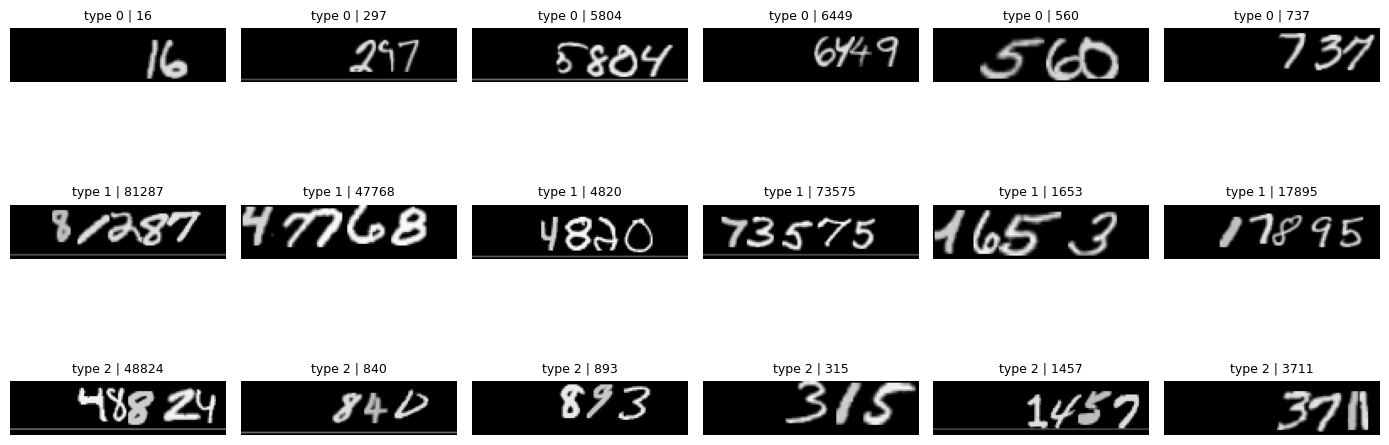

{0: 13520, 1: 660, 2: 820}


In [4]:
types = np.unique(A["type_train"])
fig, axes = plt.subplots(len(types), 6, figsize=(14, 2.1 * len(types)))
for r, t in enumerate(types):
    idx = np.where(A["type_train"] == t)[0][:6]
    for c in range(6):
        axes[r, c].axis("off")
        axes[r, c].imshow(XA["train"][idx[c], :, :, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"type {t} | {A['montant_train'][idx[c]]}", fontsize=9)
plt.tight_layout(); plt.show()
print({int(t): int((A["type_train"] == t).sum()) for t in types})

## 3. Fonctions utilitaires

| Fonction | Rôle |
|---|---|
| `vers_positions(montants)` | Transforme `'42'` en 5 cibles `[2, 4, 10, 10, 10]` (unités d'abord, 10 = position vide). Ce sont les étiquettes des 5 têtes. |
| `predire_probs(model, X)` | Probabilités des 5 têtes, tableau `(N, 5, 11)`. |
| `lire_probs(probs)` | Classe gagnante de chaque tête, d'où le montant lu, et confiance (produit des 5 probabilités maximales). |
| `exactitude_par_position`, `exactitude_par_longueur` | Exactitude de chaque tête ; exactitude du montant entier selon le nombre de chiffres. |
| `decaler(X, max_px, rng)` | Augmentation : décalage horizontal aléatoire de -`max_px` à +`max_px` pixels, bord libéré rempli de noir. |
| `journaliser`, `journaliser_une_fois` | Ajoutent une expérience dans `journal.jsonl` ; la seconde n'écrit pas deux fois la même entrée si on relance la cellule. |
| `sauver_histoire`, `lire_histoire` | Enregistrent et relisent les courbes d'entraînement. |

Le décalage de ±4 pixels : à chaque époque, chaque image d'entraînement est déplacée sur le côté d'un nombre de pixels tiré entre -4 et +4. Les chiffres tombent à des endroits légèrement différents, ce qui empêche le modèle de mémoriser des positions exactes. Il n'est appliqué qu'à l'entraînement, jamais à la validation ni au test.

In [5]:
def vers_positions(montants):
    Y = np.full((len(montants), L_MAX), EMPTY, dtype=int)
    for i, m in enumerate(montants):
        for k, ch in enumerate(str(m)[::-1]):
            Y[i, k] = int(ch)
    return Y

def predire_probs(model, X):
    P = model.predict(X, batch_size=512, verbose=0)
    return np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)      # (N, 5, 11)

def lire_probs(probs):
    cls = probs.argmax(2)
    conf = probs.max(2).prod(1)
    lus = np.array(["".join(str(c) for c in ligne[::-1] if c != EMPTY) for ligne in cls])
    return lus, conf

def exactitude_par_position(probs, Y):
    return [float(np.mean(probs[:, k].argmax(1) == Y[:, k])) for k in range(L_MAX)]

def exactitude_par_longueur(lus, montants):
    lg = np.char.str_len(montants)
    out = {}
    for n in range(1, L_MAX + 1):
        sel = lg == n
        if sel.any():
            out[n] = (float(np.mean(lus[sel] == montants[sel])), int(sel.sum()))
    return out

def journaliser(jalon, nom, **infos):
    with open("journal.jsonl", "a") as f:
        f.write(json.dumps({"jalon": jalon, "nom": nom, "t": time.strftime("%F %T"), **infos},
                           default=float) + "\n")

def decaler(X, max_px, rng):
    """Décalage horizontal aléatoire (axe largeur) pour des images (N, H, W, 1)."""
    out = np.zeros_like(X)
    W = X.shape[2]
    for i, d_ in enumerate(rng.integers(-max_px, max_px + 1, len(X))):
        if d_ >= 0:
            out[i, :, d_:, :] = X[i, :, :W - d_, :]
        else:
            out[i, :, :W + d_, :] = X[i, :, -d_:, :]
    return out

def labels_onehot(Y):
    return {f"pos{k}": keras.utils.to_categorical(Y[:, k], N_CLASSES) for k in range(L_MAX)}

Y_train = vers_positions(A["montant_train"]); Y_val = vers_positions(A["montant_val"])
Y_test = vers_positions(A["montant_test"])
T_train, T_val = labels_onehot(Y_train), labels_onehot(Y_val)

# Cible binaire "altéré" + pondération (code de démarrage du jalon 2)
ALT = {s: A["altere_" + s] for s in SPLITS}
n0, n1 = np.bincount(ALT["train"])
poids_alteration = {0: 1.0, 1: n0 / n1}
print("chèques altérés (train) :", n1, "sur", n0 + n1)

chèques altérés (train) : 1480 sur 15000


In [ ]:
def journaliser_une_fois(jalon, nom, **infos):
    """Comme journaliser, mais n'écrit rien si une entrée de même nom existe déjà."""
    if os.path.exists("journal.jsonl"):
        for ligne in open("journal.jsonl"):
            if ligne.strip() and (lambda e: e["jalon"] == jalon and e["nom"] == nom)(json.loads(ligne)):
                return
    journaliser(jalon, nom, **infos)

def sauver_histoire(cle, H, fichier="histories_jalon2.json"):
    d = json.load(open(fichier)) if os.path.exists(fichier) else {}
    d[cle] = H
    json.dump(d, open(fichier, "w"))

def lire_histoire(cle, fichier="histories_jalon2.json"):
    return json.load(open(fichier))[cle]

## 4. MLP de référence

Le MLP est le comparateur à battre. C'est la configuration retenue au jalon 1 : aplatissement, trois couches denses (512, 256, 128, ReLU, dropout 0,3) et cinq têtes softmax de 11 classes, soit 2 268 983 paramètres.

Budget d'entraînement commun à tous les modèles de lecture : 80 époques, Adam à 1e-3, lots de 128, décalage ±4 px, graine 0, modèle de la dernière époque.

`entrainer` est la boucle commune au MLP et aux CNN : elle entraîne une époque à la fois (avec un nouveau décalage aléatoire), mesure l'exactitude du montant entier sur la validation et sur 3 000 images fixes du train, puis écrit le résultat dans le journal.

In [ ]:
IDX_TR = np.arange(3000)   # sous-ensemble fixe du train pour mesurer l'exactitude à chaque époque

def build_mlp(widths=(512, 256, 128), drop=0.3, lr=1e-3, nom="mlp"):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1), name="image")
    x = layers.Flatten()(inp)
    for i, w in enumerate(widths):
        x = layers.Dense(w, activation="relu", name=f"dense_{i+1}")(x)
        if drop:
            x = layers.Dropout(drop)(x)
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(x)
               for k in range(L_MAX)}
    m = keras.Model(inp, sorties, name=nom)
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss={f"pos{k}": keras.losses.CategoricalCrossentropy() for k in range(L_MAX)})
    return m

def entrainer(nom, builder, epochs=80, aug=4, batch=128, jalon=2, seed=SEED, **params):
    """Entraîne un modèle à 5 têtes ; garde la dernière époque ; journalise (graine, exactitude train et val)."""
    keras.utils.set_random_seed(seed)
    rng = np.random.default_rng(seed)
    m = builder(nom=nom, **params)
    H = {"loss_tr": [], "loss_va": [], "exact_va": [], "exact_tr": []}
    t0 = time.time()
    for e in range(epochs):
        Xe = decaler(XA["train"], aug, rng) if aug else XA["train"]
        h = m.fit(Xe, T_train, validation_data=(XA["val"], T_val),
                  epochs=1, batch_size=batch, verbose=0)
        H["loss_tr"].append(h.history["loss"][0]); H["loss_va"].append(h.history["val_loss"][0])
        lus_v, _ = lire_probs(predire_probs(m, XA["val"]))
        H["exact_va"].append(float(np.mean(lus_v == A["montant_val"])))
        lus_t, _ = lire_probs(predire_probs(m, XA["train"][IDX_TR]))
        H["exact_tr"].append(float(np.mean(lus_t == A["montant_train"][IDX_TR])))
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | perte val {H['loss_va'][-1]:.3f} | "
                  f"exact train {H['exact_tr'][-1]:.3f} | exact val {H['exact_va'][-1]:.3f}")
    pv = predire_probs(m, XA["val"]); lus, _ = lire_probs(pv)
    res = dict(params=params, seed=seed, aug=aug, epochs=epochs, batch=batch,
               nb_params=int(m.count_params()),
               exact_val=float(np.mean(lus == A["montant_val"])),
               moy5_val=float(np.mean(H["exact_va"][-5:])), moy5_train=float(np.mean(H["exact_tr"][-5:])),
               acc_pos_val=exactitude_par_position(pv, Y_val),
               loss_val=H["loss_va"][-1], duree_s=round(time.time() - t0))
    journaliser(jalon, nom, **res)
    print(nom, "| exact val =", round(res["exact_val"], 4), "| moy 5 dern. =", round(res["moy5_val"], 4),
          "| params =", res["nb_params"], "| durée =", res["duree_s"], "s")
    return m, H, res

In [6]:
if os.path.exists("mlp_base_80ep.keras"):
    mlp_base = keras.models.load_model("mlp_base_80ep.keras")
else:
    mlp_base, H_mlp, res_mlp = entrainer("mlp_baseline_80ep", build_mlp, epochs=80, aug=4,
                                         widths=(512, 256, 128), drop=0.3, lr=1e-3)
    mlp_base.save("mlp_base_80ep.keras")

  époque  10 | perte val 6.949 | exact train 0.065 | exact val 0.065
  époque  20 | perte val 6.542 | exact train 0.115 | exact val 0.088
  époque  30 | perte val 6.326 | exact train 0.154 | exact val 0.096
  époque  40 | perte val 6.144 | exact train 0.178 | exact val 0.114
  époque  50 | perte val 6.019 | exact train 0.206 | exact val 0.120
  époque  60 | perte val 5.929 | exact train 0.226 | exact val 0.128
  époque  70 | perte val 5.855 | exact train 0.245 | exact val 0.135
  époque  80 | perte val 5.835 | exact train 0.263 | exact val 0.135
mlp_baseline_80ep | exact val = 0.135 | moy 5 dern. = 0.1367 | params = 2268983 | durée = 208 s


## 5. Vérification théorique

Architecture : trois blocs (convolution 3×3 `same`, max-pooling 2×2) à 32, 64 et 64 filtres, puis une couche dense de 128 neurones et cinq têtes de 11 classes. Le calcul se fait d'abord à la main, puis on le compare à `summary()`.

- **Dimensions.** `same` conserve la taille, le pooling la divise par 2 : 32×128, puis 16×64, 8×32, 4×16.
- **Paramètres.** Convolution : 3·3·(canaux d'entrée)·(filtres) + filtres. Dense : entrées·sorties + sorties. Le pooling n'a aucun paramètre.
- **Champ réceptif.** C'est la zone de l'image qui influence un neurone. On le suit avec le saut `j`, la distance en pixels entre deux neurones voisins de la carte (1 au départ). Une convolution 3×3 ajoute 2·j. Un pooling 2×2 ajoute j, puis le saut double.

In [7]:
def theorie_cnn(filtres=(32, 64, 64), noyau=3, dense=128):
    """Dimensions, paramètres et champ réceptif couche par couche (calcul à la main)."""
    h, w, c = IMG_H, IMG_W, 1
    rf, saut = 1, 1
    lignes = []
    for nf in filtres:
        rf += (noyau - 1) * saut                  # convolution : +(k-1) x saut
        lignes.append(dict(couche=f"Conv {noyau}x{noyau} ({nf})", sortie=f"{h}x{w}x{nf}",
                           parametres=noyau * noyau * c * nf + nf, champ_receptif=rf))
        c = nf
        rf += saut; saut *= 2; h //= 2; w //= 2   # pooling 2x2 : +saut, puis le saut double
        lignes.append(dict(couche="MaxPool 2x2", sortie=f"{h}x{w}x{c}", parametres=0, champ_receptif=rf))
    plat = h * w * c
    lignes.append(dict(couche="Flatten", sortie=str(plat), parametres=0, champ_receptif=rf))
    lignes.append(dict(couche=f"Dense {dense}", sortie=str(dense),
                       parametres=plat * dense + dense, champ_receptif="-"))
    lignes.append(dict(couche="5 têtes (11 classes)", sortie="5x11",
                       parametres=L_MAX * (dense * N_CLASSES + N_CLASSES), champ_receptif="-"))
    return pd.DataFrame(lignes), rf

theorie, RF_FINAL = theorie_cnn()
display(theorie)
TOTAL_MAIN = int(theorie["parametres"].sum())
print("Total des paramètres (à la main) :", f"{TOTAL_MAIN:,}".replace(",", " "))
print(f"Champ réceptif final : {RF_FINAL} px | hauteur d'un chiffre : 18 à 26 px")

,couche,sortie,parametres,champ_receptif
0,Conv 3x3 (32),32x128x32,320,3
1,MaxPool 2x2,16x64x32,0,4
2,Conv 3x3 (64),16x64x64,18496,8
3,MaxPool 2x2,8x32x64,0,10
4,Conv 3x3 (64),8x32x64,36928,18
5,MaxPool 2x2,4x16x64,0,22
6,Flatten,4096,0,22
7,Dense 128,128,524416,-
8,5 têtes (11 classes),5x11,7095,-


Total des paramètres (à la main) : 587 255
Champ réceptif final : 22 px | hauteur d'un chiffre : 18 à 26 px


Vérification par le code : le modèle Keras de même architecture, et le calcul du champ réceptif couche par couche.

In [8]:
def build_cnn_theorie(nom="cnn_theorie"):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1), name="image")
    x = inp
    for f in (32, 64, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(x)
               for k in range(L_MAX)}
    return keras.Model(inp, sorties, name=nom)

m_theorie = build_cnn_theorie()
m_theorie.summary()
print("Total attendu à la main :", f"{TOTAL_MAIN:,}".replace(",", " "), "| Keras :", m_theorie.count_params())

# Champ réceptif : (type, taille noyau, pas)
couches = [("conv", 3, 1), ("pool", 2, 2)] * 3
r, j = 1, 1
for t, k, s in couches:
    r = r + (k - 1) * j
    j = j * s
    print(f"après {t} : champ = {r} px, saut = {j} px")

Model: "cnn_theorie"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 128,   │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 128,   │        320 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 32, 64) │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 32, 64) │     36,928 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 4, 16, 64) │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4096)      │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_128 (Dense)   │ (None, 128)       │    524,416 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos0 (Dense)        │ (None, 11)        │      1,419 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos1 (Dense)        │ (None, 11)        │      1,419 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos2 (Dense)        │ (None, 11)        │      1,419 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos3 (Dense)        │ (None, 11)        │      1,419 │ dense_128[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos4 (Dense)        │ (None, 11)        │      1,419 │ dense_128[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 587,255 (2.24 MB)

 Trainable params: 587,255 (2.24 MB)

 Non-trainable params: 0 (0.00 B)

Total attendu à la main : 587 255 | Keras : 587255
après conv : champ = 3 px, saut = 1 px
après pool : champ = 4 px, saut = 2 px
après conv : champ = 8 px, saut = 2 px
après pool : champ = 10 px, saut = 4 px
après conv : champ = 18 px, saut = 4 px
après pool : champ = 22 px, saut = 8 px


**Ce que voit un neurone de la dernière carte.** Un carré de 22 × 22 pixels, proche de la hauteur d'un chiffre (18 à 26 px). Il voit donc à peu près un chiffre, mais un chiffre de 26 px ne rentre pas en entier, et horizontalement la zone déborde sur les voisins. La carte finale 4 × 16 contient des morceaux de chiffres : c'est la couche dense qui les assemble et qui décide pour chaque position, car elle reçoit toute la carte avec ses coordonnées. Elle porte aussi l'essentiel des paramètres (524 416 sur 587 255, soit 89 %).

## 6. Étude de conception du CNN

Le CNN a les mêmes cinq têtes que le MLP. On part d'une base (3 blocs, noyau 3, max-pooling, flatten, dense 128, dropout 0,3) et on change une seule chose à la fois :

- le nombre de blocs (2, puis 4) ;
- la taille du noyau (5 au lieu de 3) ;
- le pooling (moyen au lieu de max) ;
- l'agrégation finale (moyenne globale, GAP, au lieu de flatten).

Chaque variante est entraînée 30 époques. Le score d'une époque oscille de ±0,02 à 0,03, donc la mesure est la moyenne des 5 dernières époques. Trois graines pour la base, le pooling moyen, 4 blocs et noyau 5 ; une seule pour 2 blocs et GAP, dont l'écart à la base est de toute façon énorme. Les runs déjà faits sont relus dans `resultats_design.json`.

`build_cnn` construit le modèle à partir de ces choix, `champ_receptif` calcule la zone vue par un neurone de la dernière carte.

In [ ]:
def build_cnn(filters=(32, 64, 64), kernel=3, pool="max", agg="flatten",
              dense=128, drop=0.3, lr=1e-3, nom="cnn"):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1), name="image")
    x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x) if pool == "max" else layers.AveragePooling2D(2)(x)
    x = layers.Flatten()(x) if agg == "flatten" else layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu", name="dense_cnn")(x)
    if drop:
        x = layers.Dropout(drop)(x)
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(x)
               for k in range(L_MAX)}
    m = keras.Model(inp, sorties, name=nom)
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss={f"pos{k}": keras.losses.CategoricalCrossentropy() for k in range(L_MAX)})
    return m

def champ_receptif(kernel, n_blocs):
    r, j = 1, 1
    for _ in range(n_blocs):
        r += (kernel - 1) * j      # convolution
        r += (2 - 1) * j; j *= 2   # pooling 2x2
    return r

In [9]:
EPOCHS_DESIGN = 30
SEEDS = (0, 1, 2)
BASE = dict(filters=(32, 64, 64), kernel=3, pool="max", agg="flatten")
CONFIGS = {
    "base":    (dict(BASE), SEEDS),
    "avgpool": (dict(BASE, pool="avg"), SEEDS),
    "blocs4":  (dict(BASE, filters=(32, 64, 64, 64)), SEEDS),
    "noyau5":  (dict(BASE, kernel=5), SEEDS),
    "blocs2":  (dict(BASE, filters=(32, 64)), (0,)),
    "gap":     (dict(BASE, agg="gap"), (0,)),
}
FICHIER = "resultats_design.json"
RESULTATS = json.load(open(FICHIER)) if os.path.exists(FICHIER) else {}

for cfg, (p, seeds) in CONFIGS.items():
    for s in seeds:
        cle = f"{cfg}_s{s}"
        if cle in RESULTATS:
            print("déjà fait :", cle); continue
        print(f"\n=== {cle} ===")
        m, H, res = entrainer(cle + "_30ep", build_cnn, epochs=EPOCHS_DESIGN, aug=4,
                              dense=128, drop=0.3, lr=1e-3, seed=s, **p)
        RESULTATS[cle] = dict(config=cfg, seed=s, nb_params=res["nb_params"], H=H)
        json.dump(RESULTATS, open(FICHIER, "w"))
        del m; keras.backend.clear_session()
print("\nterminé :", len(RESULTATS), "runs")


=== base_s0 ===
  époque  10 | perte val 3.477 | exact train 0.387 | exact val 0.352
  époque  20 | perte val 2.660 | exact train 0.591 | exact val 0.463
  époque  30 | perte val 2.461 | exact train 0.678 | exact val 0.486
base_s0_30ep | exact val = 0.4863 | moy 5 dern. = 0.4935 | params = 587255 | durée = 161 s

=== base_s1 ===
  époque  10 | perte val 2.963 | exact train 0.499 | exact val 0.407
  époque  20 | perte val 2.444 | exact train 0.679 | exact val 0.478
  époque  30 | perte val 2.246 | exact train 0.798 | exact val 0.523
base_s1_30ep | exact val = 0.5227 | moy 5 dern. = 0.519 | params = 587255 | durée = 146 s

=== base_s2 ===
  époque  10 | perte val 3.235 | exact train 0.448 | exact val 0.379
  époque  20 | perte val 2.636 | exact train 0.610 | exact val 0.468
  époque  30 | perte val 2.335 | exact train 0.727 | exact val 0.524
base_s2_30ep | exact val = 0.524 | moy 5 dern. = 0.5127 | params = 587255 | durée = 146 s

=== avgpool_s0 ===
  époque  10 | perte val 3.689 | exac

In [10]:
RF = {"base": champ_receptif(3, 3), "avgpool": champ_receptif(3, 3), "blocs4": champ_receptif(3, 4),
      "noyau5": champ_receptif(5, 3), "blocs2": champ_receptif(3, 2), "gap": champ_receptif(3, 3)}
ORDRE = ["blocs2", "base", "avgpool", "gap", "noyau5", "blocs4"]

def m5(H, cle): return float(np.mean(H[cle][EPOCHS_DESIGN - 5:EPOCHS_DESIGN]))

SYNTH = {}
for cfg in ORDRE:
    runs = [r for r in RESULTATS.values() if r["config"] == cfg]
    if not runs: continue
    va = np.array([m5(r["H"], "exact_va") for r in runs])
    tr = np.array([m5(r["H"], "exact_tr") for r in runs])
    SYNTH[cfg] = dict(n=len(runs), params=runs[0]["nb_params"], rf=RF[cfg], va_moy=va.mean(),
                      va_std=va.std(ddof=1) if len(va) > 1 else float("nan"), tr_moy=tr.mean())

print(len(RESULTATS), "runs chargés\n")
print(f"{'config':10s}{'runs':>5s}{'params':>11s}{'champ':>7s}{'val exact (moy ± std)':>24s}{'train exact':>13s}{'écart':>8s}")
for c, v in SYNTH.items():
    print(f"{c:10s}{v['n']:5d}{v['params']:11,d}{v['rf']:7d}"
          f"{v['va_moy']:13.3f} ± {v['va_std']:.3f}{v['tr_moy']:13.3f}{v['tr_moy'] - v['va_moy']:8.3f}")
print("\nécart = train - val (grand écart : sur-apprentissage).")
print("std = écart-type entre graines (3 graines pour base, avgpool, blocs4, noyau5 ; 1 seule pour blocs2 et gap, donc pas de std).")
print("Des écarts de val plus petits que le std ne sont pas significatifs.")

14 runs chargés

config     runs     params  champ   val exact (moy ± std)  train exact   écart
blocs2        1  2,123,191     10        0.353 ± nan        0.599   0.246
base          3    587,255     22        0.508 ± 0.013        0.713   0.204
avgpool       3    587,255     22        0.448 ± 0.028        0.604   0.156
gap           1     71,159     22        0.069 ± nan        0.062  -0.007
noyau5        3    686,071     36        0.650 ± 0.031        0.861   0.211
blocs4        3    230,967     46        0.645 ± 0.032        0.753   0.108

écart = train - val (grand écart : sur-apprentissage).
std = écart-type entre graines (3 graines pour base, avgpool, blocs4, noyau5 ; 1 seule pour blocs2 et gap, donc pas de std).
Des écarts de val plus petits que le std ne sont pas significatifs.


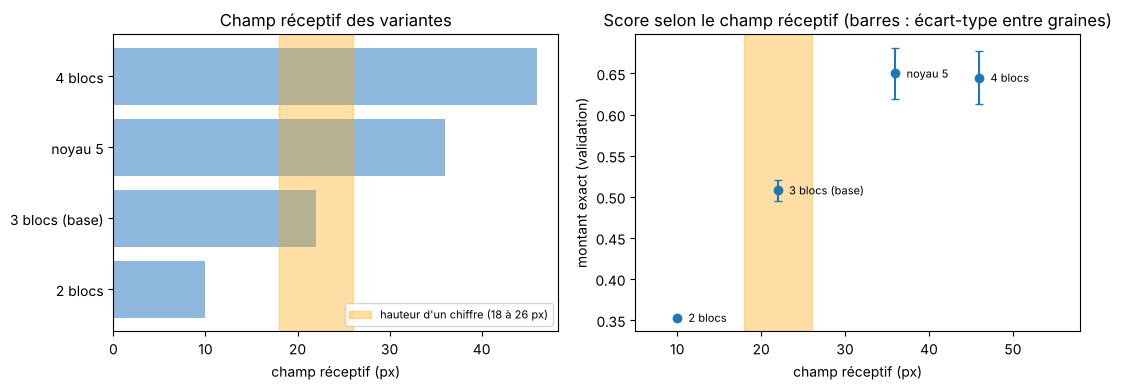

In [11]:
ordre = ["blocs2", "base", "noyau5", "blocs4"]
noms = {"blocs2": "2 blocs", "base": "3 blocs (base)", "noyau5": "noyau 5", "blocs4": "4 blocs"}
rf = [SYNTH[c]["rf"] for c in ordre]
score = [SYNTH[c]["va_moy"] for c in ordre]
ecart = [0 if np.isnan(SYNTH[c]["va_std"]) else SYNTH[c]["va_std"] for c in ordre]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh([noms[c] for c in ordre], rf, color="#8fb8de")
ax[0].axvspan(18, 26, color="orange", alpha=0.35, label="hauteur d'un chiffre (18 à 26 px)")
ax[0].set_xlabel("champ réceptif (px)"); ax[0].set_title("Champ réceptif des variantes")
ax[0].legend(loc="lower right", fontsize=8)

ax[1].errorbar(rf, score, yerr=ecart, fmt="o", capsize=3)
for c, x_, s_ in zip(ordre, rf, score):
    ax[1].annotate(noms[c], (x_, s_), textcoords="offset points", xytext=(8, -3), fontsize=8)
ax[1].axvspan(18, 26, color="orange", alpha=0.35)
ax[1].set_xlim(5, 58)
ax[1].set_xlabel("champ réceptif (px)"); ax[1].set_ylabel("montant exact (validation)")
ax[1].set_title("Score selon le champ réceptif (barres : écart-type entre graines)")
plt.tight_layout(); plt.show()

**Lecture.**
- Plus le champ réceptif est grand, meilleur est le score : 10 px, 0,35 ; 22 px, 0,51 ; 36 et 46 px, 0,65. Les deux façons de l'agrandir (4 blocs, noyau 5) gagnent environ 0,14, bien plus que l'écart entre graines (0,01 à 0,03).
- Le nombre de paramètres n'explique pas l'écart : 2 blocs en a le plus (2,1 M) et le pire score, 4 blocs en a 231 k et égale noyau 5 (686 k). Ces résultats vont dans le sens d'un effet du champ réceptif sans le prouver : passer à 4 blocs change aussi la profondeur et la taille du flatten.
- GAP s'effondre (0,069) et n'apprend même pas l'entraînement (0,062). Sans l'information de position, la tête des unités ne peut pas distinguer les unités des dizaines : c'est le rôle du flatten et de la couche dense.
- Le pooling max (0,508) fait mieux que le pooling moyen (0,448), avec 3 graines seulement.
- Noyau 5 et 4 blocs sont à égalité (0,005 d'écart pour un écart-type de 0,03). La zone orange du graphique montre la hauteur d'un chiffre : les deux meilleures variantes la dépassent largement et voient donc probablement aussi les chiffres voisins.

## 7. CNN final et comparaison au MLP

Règle de choix, appliquée par le code : on prend la meilleure moyenne, on garde les variantes à moins d'un écart-type d'elle, puis celle qui a le moins de paramètres. Le modèle retenu est ensuite entraîné 80 époques, comme le MLP.

In [12]:
cands = {c: v for c, v in SYNTH.items() if v["n"] >= 3}
meilleur = max(cands, key=lambda c: cands[c]["va_moy"])
seuil = cands[meilleur]["va_moy"] - cands[meilleur]["va_std"]
proches = [c for c in cands if cands[c]["va_moy"] >= seuil]
CHOIX = min(proches, key=lambda c: cands[c]["params"])
print("meilleure moyenne :", meilleur, "| dans le bruit :", proches, "| choix (moins de paramètres) :", CHOIX)

meilleure moyenne : noyau5 | dans le bruit : ['blocs4', 'noyau5'] | choix (moins de paramètres) : blocs4


In [13]:
if os.path.exists("cnn_final_80ep.keras"):
    cnn_final = keras.models.load_model("cnn_final_80ep.keras")
    H_final = lire_histoire("final")
else:
    cnn_final, H_final, _ = entrainer("cnn_final_80ep", build_cnn, epochs=80, aug=4,
                                      dense=128, drop=0.3, lr=1e-3, seed=0, **CONFIGS[CHOIX][0])
    cnn_final.save("cnn_final_80ep.keras")
    sauver_histoire("final", H_final)
res_final = dict(moy5_train=float(np.mean(H_final["exact_tr"][-5:])),
                 moy5_val=float(np.mean(H_final["exact_va"][-5:])))

  époque  10 | perte val 3.106 | exact train 0.427 | exact val 0.391
  époque  20 | perte val 1.967 | exact train 0.628 | exact val 0.576
  époque  30 | perte val 1.626 | exact train 0.725 | exact val 0.642
  époque  40 | perte val 1.539 | exact train 0.774 | exact val 0.659
  époque  50 | perte val 1.273 | exact train 0.838 | exact val 0.697
  époque  60 | perte val 1.209 | exact train 0.885 | exact val 0.736
  époque  70 | perte val 1.181 | exact train 0.902 | exact val 0.743
  époque  80 | perte val 1.149 | exact train 0.905 | exact val 0.757
cnn_final_80ep | exact val = 0.7567 | moy 5 dern. = 0.7467 | params = 230967 | durée = 370 s


`comparer` affiche, pour plusieurs modèles, l'exactitude position par position et par longueur de montant, le montant entier exact et le nombre de paramètres.

                                 MLP     CNN final
unités                         0.676         0.977
dizaines                       0.409         0.936
centaines                      0.461         0.885
milliers                       0.631         0.911
dizaines de milliers           0.844         0.963
--------------------------------------------------
1 chiffre(s) (n=137)           0.825         1.000
2 chiffre(s) (n=467)           0.379         0.929
3 chiffre(s) (n=985)           0.107         0.874
4 chiffre(s) (n=907)           0.009         0.706
5 chiffre(s) (n=504)           0.004         0.393
--------------------------------------------------
montant exact                  0.135         0.757
paramètres                 2,268,983       230,967


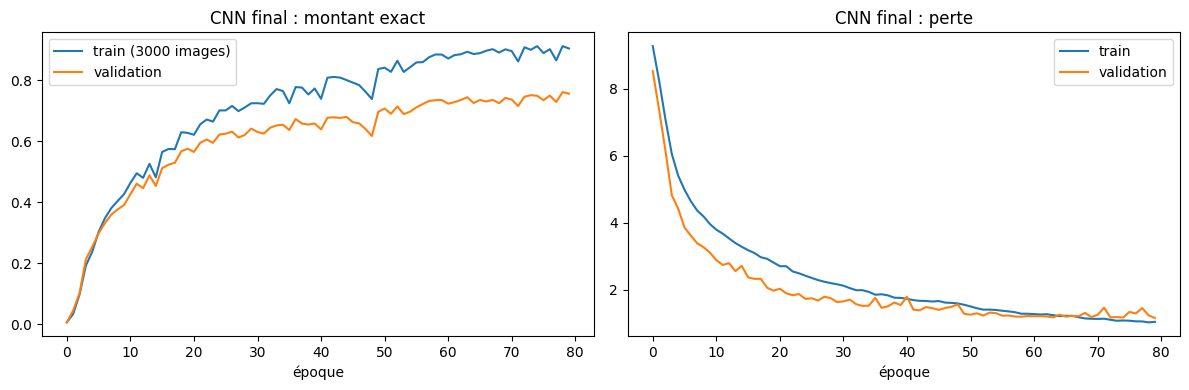

écart train - val (moy 5 dern. époques) : 0.149


In [14]:
def comparer(modeles, noms):
    lus_pv = {}
    for m, n in zip(modeles, noms):
        pv = predire_probs(m, XA["val"]); lus, _ = lire_probs(pv)
        lus_pv[n] = (pv, lus)
    print(f"{'':22s}" + "".join(f"{n:>14s}" for n in noms))
    for k in range(L_MAX):
        print(f"{NOMS_POS[k]:22s}" + "".join(
            f"{exactitude_par_position(lus_pv[n][0], Y_val)[k]:14.3f}" for n in noms))
    print("-" * (22 + 14 * len(noms)))
    for L in range(1, L_MAX + 1):
        row = [exactitude_par_longueur(lus_pv[n][1], A["montant_val"])[L] for n in noms]
        print(f"{str(L) + ' chiffre(s) (n=' + str(row[0][1]) + ')':22s}" + "".join(f"{r[0]:14.3f}" for r in row))
    print("-" * (22 + 14 * len(noms)))
    print(f"{'montant exact':22s}" + "".join(
        f"{float(np.mean(lus_pv[n][1] == A['montant_val'])):14.3f}" for n in noms))
    print(f"{'paramètres':22s}" + "".join(f"{m.count_params():14,d}" for m in modeles))

comparer([mlp_base, cnn_final], ["MLP", "CNN final"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(H_final["exact_tr"], label="train (3000 images)"); ax[0].plot(H_final["exact_va"], label="validation")
ax[0].set_title("CNN final : montant exact"); ax[0].legend()
ax[1].plot(H_final["loss_tr"], label="train"); ax[1].plot(H_final["loss_va"], label="validation")
ax[1].set_title("CNN final : perte"); ax[1].legend()
for a in ax: a.set_xlabel("époque")
plt.tight_layout(); plt.show()
print("écart train - val (moy 5 dern. époques) :",
      round(res_final["moy5_train"] - res_final["moy5_val"], 3))

**Lecture.**
- Montant exact en validation : 0,757 pour le CNN (0,747 en moyenne sur les 5 dernières époques) contre 0,135 pour le MLP, avec 231 k paramètres au lieu de 2,27 M. Le MLP doit réapprendre chaque chiffre à chaque endroit ; les filtres du CNN, partagés sur toute l'image, le font une seule fois.
- Toutes les positions sont lues bien au-dessus de la réponse constante, y compris les dizaines de milliers (0,963 contre 0,832 pour « toujours vide »), que le MLP n'apprenait pas.
- Par longueur : 1,000 pour 1 chiffre, 0,929, 0,874, 0,706, puis 0,393 pour 5 chiffres. L'écart restant vient des montants de 4 et 5 chiffres, où cinq têtes doivent toutes avoir raison.
- Passer de 30 à 80 époques a fait monter la validation de 0,642 à 0,757 : le modèle n'avait pas fini d'apprendre à 30 époques. Entraînement 0,905 contre validation 0,757, donc un sur-apprentissage modéré, et la validation montait encore à l'époque 80.

## 8. Détecteur d'altération

CNN binaire : mêmes quatre blocs que le CNN retenu, dense 128, dropout 0,3, une sortie sigmoïde. La cible est « chèque altéré ». Comme il n'y a qu'environ 10 % de positifs, on utilise `poids_alteration` (code de démarrage) comme poids de classe. Décalage ±4 px. L'époque retenue est choisie automatiquement sur l'AUC de validation.

In [ ]:
def build_detecteur(filters=(32, 64, 64, 64), kernel=3, dense=128, drop=0.3, lr=1e-3, nom="detecteur"):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1))
    x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense, activation="relu")(x)
    x = layers.Dropout(drop)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out, name=nom)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return m

def entrainer_detecteur(nom, epochs=40, aug=4, batch=128, seed=SEED, **params):
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed)
    m = build_detecteur(nom=nom, **params)
    meilleur, poids, hist = -1, None, {"auc_val": [], "loss_val": []}
    t0 = time.time()
    for e in range(epochs):
        Xe = decaler(XA["train"], aug, rng) if aug else XA["train"]
        m.fit(Xe, ALT["train"], epochs=1, batch_size=batch, class_weight=poids_alteration, verbose=0)
        s = m.predict(XA["val"], batch_size=512, verbose=0).ravel()
        auc = roc_auc_score(ALT["val"], s)
        hist["auc_val"].append(float(auc))
        if auc > meilleur:
            meilleur, poids, ep = auc, m.get_weights(), e + 1
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | AUC val {auc:.4f}")
    m.set_weights(poids)
    journaliser(2, nom, params=params, seed=seed, aug=aug, epochs=epochs, epoque_retenue=ep,
                auc_val=float(meilleur), nb_params=int(m.count_params()), duree_s=round(time.time() - t0))
    print(nom, "| meilleure AUC val =", round(meilleur, 4), "à l'époque", ep, "| durée =", round(time.time() - t0), "s")
    return m, hist

In [15]:
if os.path.exists("detecteur_blocs4.keras"):
    det = keras.models.load_model("detecteur_blocs4.keras")
    H_det = lire_histoire("det")
else:
    det, H_det = entrainer_detecteur("detecteur_blocs4")
    det.save("detecteur_blocs4.keras")
    sauver_histoire("det", H_det)

  époque  10 | AUC val 0.9971
  époque  20 | AUC val 0.9984
  époque  30 | AUC val 0.9994
  époque  40 | AUC val 0.9986
detecteur_blocs4 | meilleure AUC val = 0.9994 à l'époque 37 | durée = 143 s


**Le seuil d'alerte.** Le détecteur donne à chaque chèque un score entre 0 et 1 ; au-dessus du seuil, le chèque part vers un opérateur. Deux erreurs ont des coûts différents :

- une fausse alerte envoie un chèque normal à un opérateur : du temps, et un chèque de moins automatisé ;
- une fraude manquée coûte bien plus à la banque que cette revue.

On choisit le seuil qui minimise `C_FA × FP + C_MISS × FN` sur la validation. Les coûts ne sont pas donnés par l'énoncé : on suppose `C_FA = 1` (une revue) et `C_MISS = 50` (une fraude manquée vaut 50 revues), puis on regarde plus bas comment le seuil bouge si ce rapport change. Le rappel à 5 % de fausses alertes est un point de comparaison de plus sur la courbe ROC.

AUC val : 0.9994
Rappel à 5 % de fausses alertes : 0.996 (seuil 0.003, FPR réel 0.045)

Au seuil 5 % :
  type 0 (normaux) : fausses alertes = 0.045 (n=2715)
  type 1 : rappel = 0.991 | manqués = 1/108
  type 2 : rappel = 1.000 | manqués = 0/177

Seuil de coût minimal (C_FA=1.0, C_MISS=50.0) : 0.016 | FPR = 0.019 | rappel = 0.993 | coût moyen par chèque = 0.051
Pour 50 000 chèques/jour : ~861 revues de chèques normaux, ~4964 fraudes détectées sur ~5000


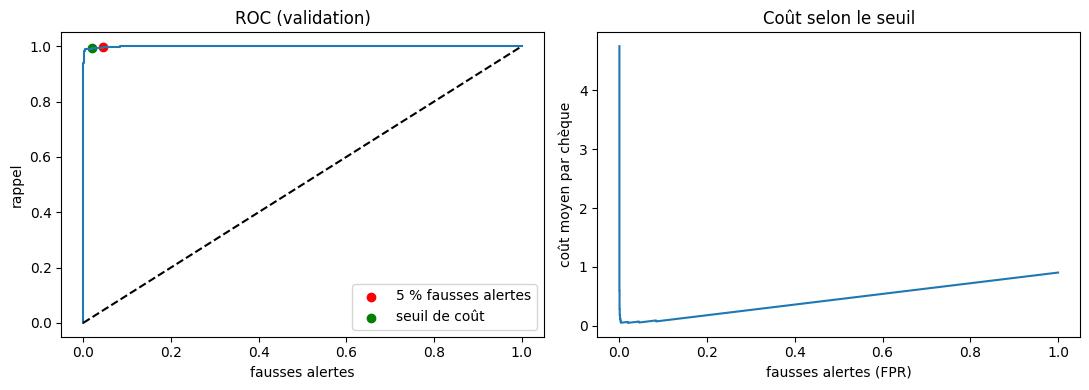

In [16]:
s_val = det.predict(XA["val"], batch_size=512, verbose=0).ravel()
y = ALT["val"]; typ = A["type_val"]
fpr, tpr, seuils = roc_curve(y, s_val)
print("AUC val :", round(roc_auc_score(y, s_val), 4))

# Point à 5 % de fausses alertes
i5 = np.where(fpr <= 0.05)[0].max()
seuil5 = seuils[i5]
print(f"Rappel à 5 % de fausses alertes : {tpr[i5]:.3f} (seuil {seuil5:.3f}, FPR réel {fpr[i5]:.3f})")

# Altérations manquées par type, à ce seuil
alerte = s_val >= seuil5
print("\nAu seuil 5 % :")
for t in np.unique(typ):
    sel = typ == t
    if t == 0:
        print(f"  type 0 (normaux) : fausses alertes = {alerte[sel].mean():.3f} (n={sel.sum()})")
    else:
        print(f"  type {t} : rappel = {alerte[sel].mean():.3f} | manqués = {int((~alerte[sel]).sum())}/{sel.sum()}")

# Seuil de coût : à TOI de fixer et justifier les coûts
C_FA, C_MISS = 1.0, 50.0        # exemple : revue = 1 unité, fraude manquée = 50 unités
n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
cout = C_FA * fpr * n_neg + C_MISS * (1 - tpr) * n_pos
ic = int(np.argmin(cout))
print(f"\nSeuil de coût minimal (C_FA={C_FA}, C_MISS={C_MISS}) : {seuils[ic]:.3f}"
      f" | FPR = {fpr[ic]:.3f} | rappel = {tpr[ic]:.3f} | coût moyen par chèque = {cout[ic]/len(y):.3f}")
print(f"Pour 50 000 chèques/jour : ~{int(fpr[ic]*0.9*50000)} revues de chèques normaux, "
      f"~{int(tpr[ic]*0.1*50000)} fraudes détectées sur ~{int(0.1*50000)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].scatter([fpr[i5]], [tpr[i5]], c="r", label="5 % fausses alertes")
ax[0].scatter([fpr[ic]], [tpr[ic]], c="g", label="seuil de coût")
ax[0].set_xlabel("fausses alertes"); ax[0].set_ylabel("rappel"); ax[0].set_title("ROC (validation)"); ax[0].legend()
ax[1].plot(fpr, cout / len(y)); ax[1].set_xlabel("fausses alertes (FPR)")
ax[1].set_ylabel("coût moyen par chèque"); ax[1].set_title("Coût selon le seuil")
plt.tight_layout(); plt.show()

Altérations manquées pour des seuils plus stricts, sensibilité au rapport de coûts, et les six altérations les moins bien détectées.

 FPR visé    seuil  rappel global   type 1   type 2
    0.002   0.8845          0.975    0.991    0.966
    0.005   0.5034          0.989    0.991    0.989
    0.010   0.5034          0.989    0.991    0.989
    0.020   0.0163          0.993    0.991    0.994
    0.050   0.0028          0.996    0.991    1.000

Sensibilité au coût (coût d'une fraude manquée / coût d'une revue) :
  ratio     5 | seuil 0.5034 | FPR 0.003 | rappel 0.989 | fraudes manquées 3/285
  ratio    10 | seuil 0.5034 | FPR 0.003 | rappel 0.989 | fraudes manquées 3/285
  ratio    50 | seuil 0.0163 | FPR 0.019 | rappel 0.993 | fraudes manquées 2/285
  ratio   200 | seuil 0.0007 | FPR 0.084 | rappel 1.000 | fraudes manquées 0/285
  ratio  1000 | seuil 0.0007 | FPR 0.084 | rappel 1.000 | fraudes manquées 0/285


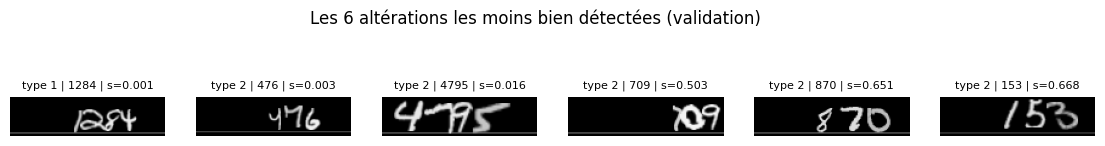

In [17]:
print(f"{'FPR visé':>9s}{'seuil':>9s}{'rappel global':>15s}{'type 1':>9s}{'type 2':>9s}")
for cible in [0.002, 0.005, 0.01, 0.02, 0.05]:
    i = np.where(fpr <= cible)[0].max()
    al = s_val >= seuils[i]
    r = {t: al[typ == t].mean() for t in (1, 2)}
    print(f"{cible:9.3f}{seuils[i]:9.4f}{tpr[i]:15.3f}{r[1]:9.3f}{r[2]:9.3f}")

print("\nSensibilité au coût (coût d'une fraude manquée / coût d'une revue) :")
for ratio in [5, 10, 50, 200, 1000]:
    c = fpr * n_neg + ratio * (1 - tpr) * n_pos
    i = int(np.argmin(c))
    print(f"  ratio {ratio:5d} | seuil {seuils[i]:.4f} | FPR {fpr[i]:.3f} | rappel {tpr[i]:.3f} | "
          f"fraudes manquées {int(round((1 - tpr[i]) * n_pos))}/{n_pos}")

pos_idx = np.where(y == 1)[0]
pires = pos_idx[np.argsort(s_val[pos_idx])[:6]]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.2))
for ax, i in zip(axes, pires):
    ax.imshow(XA["val"][i, :, :, 0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"type {typ[i]} | {A['montant_val'][i]} | s={s_val[i]:.3f}", fontsize=8)
plt.suptitle("Les 6 altérations les moins bien détectées (validation)")
plt.show()

**Lecture.**
- AUC de validation 0,9994 (cible 0,95). Rappel à 5 % de fausses alertes : 0,996, avec 1 altération manquée sur 108 pour le type 1 et 0 sur 177 pour le type 2.
- Avec un seuil plus strict (0,2 % de fausses alertes), le type 2 est un peu plus difficile (rappel 0,966 contre 0,991). Cela repose sur 7 manquées au total : c'est une tendance, pas un résultat.
- Seuil retenu pour un rapport de coûts de 50 : 0,0163, soit 1,9 % de fausses alertes et un rappel de 0,993. Si une fraude manquée vaut 5 à 10 revues, le seuil monte à 0,503 ; à 200 revues ou plus, il descend à 0,0007 avec 8,4 % de fausses alertes. Les seuils sont bas parce que les scores sont très tranchés et que les poids de classe en font autre chose que des probabilités calibrées.
- Les deux altérations manquées au seuil de coût ont des scores très bas (0,001 et 0,003) : ce sont des erreurs franches, pas des cas limites.

## 9. Scanner B, corruption et auto-encodeur débruiteur

### 9.1 Ce que le CNN fait de B

Le CNN entraîné sur A, sans rien changer, lit presque rien sur B. On compare aussi les statistiques d'intensité et quelques images.

CNN final sur B val, sans débruitage : montant exact = 0.0025 (cible finale 0,70 sur le test)
par longueur : {1: (0.0, 18), 2: (0.0, 54), 3: (0.0, 150), 4: (0.0, 120), 5: (0.017, 58)}
A | fond (médiane) = 0.000 | encre (99e percentile) = 0.937 | moyenne = 0.102 | écart-type = 0.247
B | fond (médiane) = 0.176 | encre (99e percentile) = 0.780 | moyenne = 0.222 | écart-type = 0.161


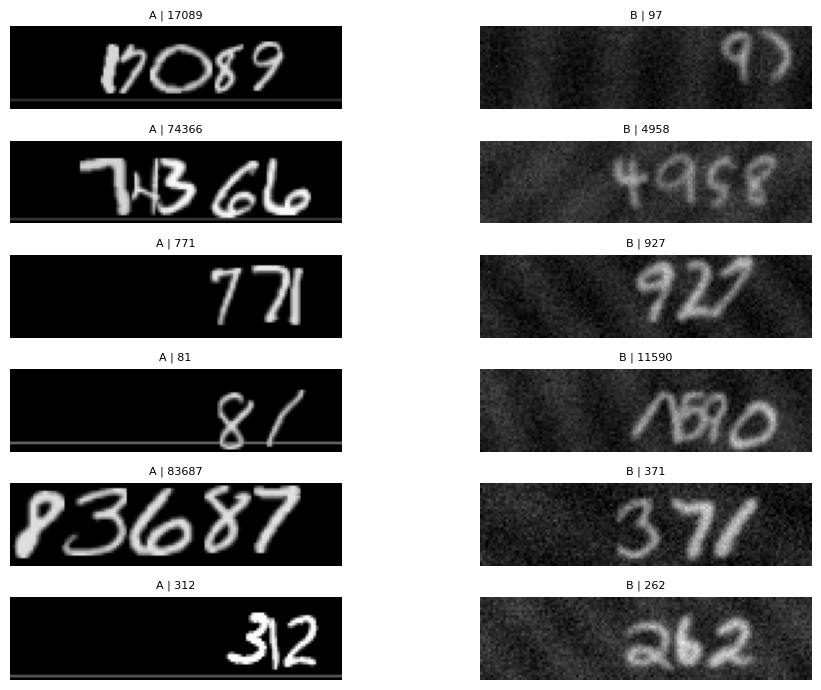

In [18]:
# Lecture de B par le CNN final, sans débruitage (validation, 400 images)
lus_b, _ = lire_probs(predire_probs(cnn_final, XB["val"]))
print("CNN final sur B val, sans débruitage : montant exact =",
      round(float(np.mean(lus_b == B["montant_val"])), 4), "(cible finale 0,70 sur le test)")
print("par longueur :", {n: (round(v[0], 3), v[1])
                         for n, v in exactitude_par_longueur(lus_b, B["montant_val"]).items()})

# Statistiques d'intensité A vs B
for nom, X in [("A", XA["val"]), ("B", XB["val"])]:
    img = X[..., 0]
    print(f"{nom} | fond (médiane) = {np.median(img):.3f} | encre (99e percentile) = "
          f"{np.percentile(img, 99):.3f} | moyenne = {img.mean():.3f} | écart-type = {img.std():.3f}")

# Images côte à côte
fig, axes = plt.subplots(6, 2, figsize=(10, 7))
for r in range(6):
    for c, (nom, X, M) in enumerate([("A", XA["val"], A), ("B", XB["val"], B)]):
        axes[r, c].imshow(X[r, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(f"{nom} | {M['montant_val'][r]}", fontsize=8)
plt.tight_layout(); plt.show()

B a un fond relevé (médiane 0,18 contre 0 pour A), une encre moins contrastée (99e percentile 0,78 contre 0,94), des raies diagonales (motif de sécurité), du grain et des traits plus flous. Les chiffres gardent la même taille et restent cadrés à droite, la rotation semble donc faible. Autre différence : A a une fine ligne grise en bas de l'image, absente de B.

A | fond par image (5/50/95 %) : [0. 0. 0.] | encre p99 par image : [0.835 0.91  0.98 ]
B | fond par image (5/50/95 %) : [0.129 0.176 0.22 ] | encre p99 par image : [0.592 0.741 0.894]
A moyenne des lignes 26 à 31 : [0.078 0.056 0.086 0.072 0.06  0.003]
B moyenne des lignes 26 à 31 : [0.204 0.191 0.178 0.167 0.16  0.156]


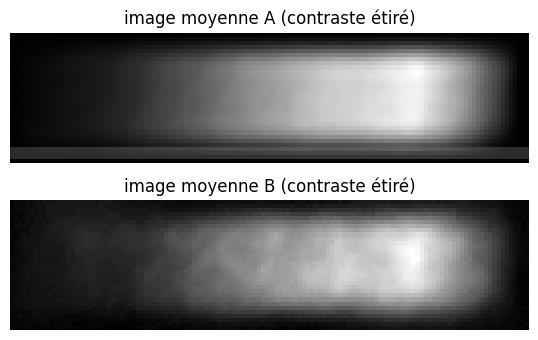

In [19]:
for nom, X in [("A", XA["train"]), ("B", XB["train"])]:
    img = X[..., 0].reshape(len(X), -1)
    med = np.median(img, axis=1); p99 = np.percentile(img, 99, axis=1)
    print(nom, "| fond par image (5/50/95 %) :", np.round(np.percentile(med, [5, 50, 95]), 3),
          "| encre p99 par image :", np.round(np.percentile(p99, [5, 50, 95]), 3))

# Ligne en bas : moyenne par ligne (6 dernières lignes)
for nom, X in [("A", XA["train"]), ("B", XB["train"])]:
    print(nom, "moyenne des lignes 26 à 31 :", np.round(X[..., 0].mean(axis=(0, 2))[26:], 3))

# Image moyenne : un motif fixe apparaît, un motif aléatoire disparaît
fig, ax = plt.subplots(2, 1, figsize=(10, 3.5))
for a, (nom, X) in zip(ax, [("A", XA["train"]), ("B", XB["train"])]):
    a.imshow(X[..., 0].mean(0), cmap="gray"); a.set_title(f"image moyenne {nom} (contraste étiré)"); a.axis("off")
plt.tight_layout(); plt.show()

### 9.2 Corruption des images de A pour imiter B

Le premier jet du sujet (encre pâle et bruit gaussien) ne reproduit ni le fond relevé, ni le flou, ni les raies. `corrompre` applique, dans l'ordre : une légère rotation (±2°), un flou gaussien, un fond relevé avec un contraste réduit, des raies diagonales, des taches lisses et un bruit granuleux. Les plages sont réglées sur les statistiques des images de B, sans utiliser ses étiquettes. `stats` résume une série d'images (fond, encre, contraste, netteté, grain) pour comparer A corrompue à B.

Version 2 : fond trop clair (0,206 contre 0,176), encre trop pâle (0,715 contre 0,780) et grain trop net.

A propre     {'fond': 0.0, 'encre_p99': 0.937, 'moyenne': 0.102, 'ecart': 0.247, 'gradient': 0.066}
A corrompue  {'fond': 0.206, 'encre_p99': 0.715, 'moyenne': 0.236, 'ecart': 0.15, 'gradient': 0.063}
B val        {'fond': 0.176, 'encre_p99': 0.78, 'moyenne': 0.222, 'ecart': 0.161, 'gradient': 0.063}
CNN sur A val corrompue : montant exact = 0.0007 | sur B val : 0.0025


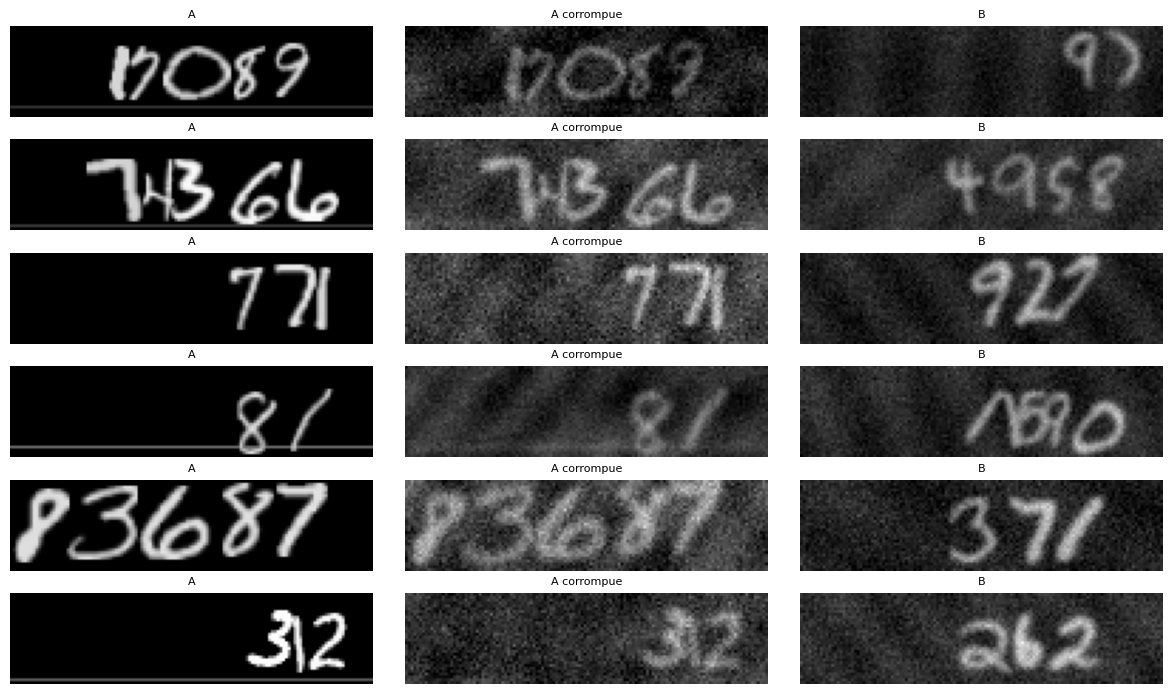

In [20]:
def corrompre_v2(X, rng, rot_max=2.0, flou=(0.6, 1.4), fond=(0.10, 0.25), contraste=(0.50, 0.70),
              raies=(0.02, 0.07), lambda_=(10, 30), taches=0.04, bruit=(0.03, 0.07)):
    N, H, W, _ = X.shape
    out = np.empty_like(X)
    yy, xx = np.mgrid[0:H, 0:W].astype("float32")
    for i in range(N):
        img = rotate(X[i, :, :, 0], rng.uniform(-rot_max, rot_max), reshape=False, order=1, mode="constant", cval=0.0)
        img = gaussian_filter(img, rng.uniform(*flou))
        img = rng.uniform(*fond) + rng.uniform(*contraste) * img
        th, lam, ph = rng.uniform(0.3, 1.2), rng.uniform(*lambda_), rng.uniform(0, 2 * np.pi)
        img = img + rng.uniform(*raies) * np.sin(2 * np.pi * (xx * np.cos(th) + yy * np.sin(th)) / lam + ph)
        t = gaussian_filter(rng.normal(0, 1, (H, W)), 5); img = img + taches * t / (t.std() + 1e-8)
        img = img + rng.normal(0, rng.uniform(*bruit), (H, W))
        out[i, :, :, 0] = np.clip(img, 0, 1)
    return out

def stats_v2(X):
    img = X[..., 0]; gy, gx = np.gradient(img, axis=(1, 2))
    return dict(fond=np.median(img), encre_p99=np.percentile(img, 99), moyenne=img.mean(),
                ecart=img.std(), gradient=np.sqrt(gx ** 2 + gy ** 2).mean())

rng_c = np.random.default_rng(SEED)
Xc_val = corrompre_v2(XA["val"], rng_c)
for nom, X in [("A propre", XA["val"]), ("A corrompue", Xc_val), ("B val", XB["val"])]:
    print(f"{nom:12s}", {k: round(float(v), 3) for k, v in stats_v2(X).items()})

# Test pratique : le CNN lit-il A corrompue aussi mal que B ?
lus_c, _ = lire_probs(predire_probs(cnn_final, Xc_val))
print("CNN sur A val corrompue : montant exact =", round(float(np.mean(lus_c == A["montant_val"])), 4),
      "| sur B val :", round(float(np.mean(lus_b == B["montant_val"])), 4))

fig, axes = plt.subplots(6, 3, figsize=(12, 7))
for r in range(6):
    for c, (nom, X) in enumerate([("A", XA["val"]), ("A corrompue", Xc_val), ("B", XB["val"])]):
        axes[r, c].imshow(X[r, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(nom, fontsize=8)
plt.tight_layout(); plt.show()

Version 3 : fond abaissé et contraste relevé, bruit lissé pour que le grain soit moins net, et une statistique de grain ajoutée.

A propre     {'fond': 0.0, 'encre_p99': 0.9373, 'moyenne': 0.1017, 'ecart': 0.2471, 'gradient': 0.0655, 'grain': 0.0}
A corrompue  {'fond': 0.1784, 'encre_p99': 0.7676, 'moyenne': 0.2177, 'ecart': 0.1644, 'gradient': 0.0635, 'grain': 0.0235}
B val        {'fond': 0.1765, 'encre_p99': 0.7804, 'moyenne': 0.2222, 'ecart': 0.1611, 'gradient': 0.0625, 'grain': 0.0285}
CNN sur A val corrompue : 0.001 | sur B val : 0.0025


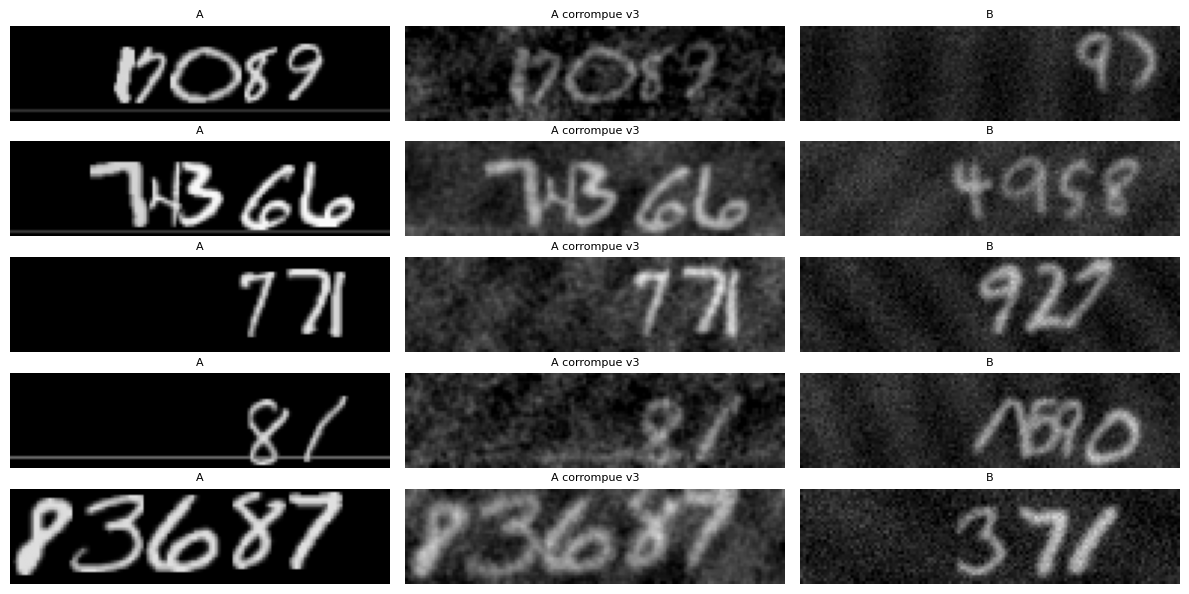

In [21]:
def corrompre(X, rng, rot_max=2.0, flou=(0.6, 1.4), fond=(0.09, 0.20), contraste=(0.55, 0.85),
              raies=(0.02, 0.07), lambda_=(10, 30), taches=0.04, bruit=(0.03, 0.07), bruit_flou=0.7):
    N, H, W, _ = X.shape
    out = np.empty_like(X)
    yy, xx = np.mgrid[0:H, 0:W].astype("float32")
    for i in range(N):
        img = rotate(X[i, :, :, 0], rng.uniform(-rot_max, rot_max), reshape=False, order=1, mode="constant", cval=0.0)
        img = gaussian_filter(img, rng.uniform(*flou))
        img = rng.uniform(*fond) + rng.uniform(*contraste) * img
        th, lam, ph = rng.uniform(0.3, 1.2), rng.uniform(*lambda_), rng.uniform(0, 2 * np.pi)
        img = img + rng.uniform(*raies) * np.sin(2 * np.pi * (xx * np.cos(th) + yy * np.sin(th)) / lam + ph)
        t = gaussian_filter(rng.normal(0, 1, (H, W)), 5); img = img + taches * t / (t.std() + 1e-8)
        n = gaussian_filter(rng.normal(0, 1, (H, W)), bruit_flou); n = n / (n.std() + 1e-8)
        img = img + rng.uniform(*bruit) * n
        out[i, :, :, 0] = np.clip(img, 0, 1)
    return out

def stats(X):
    img = X[..., 0]; gy, gx = np.gradient(img, axis=(1, 2))
    sous = img[:400]
    grain = np.median([np.median(np.abs(s - gaussian_filter(s, 1.0))) for s in sous])
    return dict(fond=np.median(img), encre_p99=np.percentile(img, 99), moyenne=img.mean(),
                ecart=img.std(), gradient=np.sqrt(gx ** 2 + gy ** 2).mean(), grain=grain)

# Journal : on garde la trace de la version 2 (mesurée plus haut)
journaliser_une_fois(2, "corruption_v2", fond=0.206, encre_p99=0.715, moyenne=0.236, ecart=0.150,
            exact_cnn_A_corrompue=0.0007, exact_cnn_B=0.0025,
            remarque="grain trop net, encre trop pâle, fond trop clair")

rng_c = np.random.default_rng(SEED)
Xc_val = corrompre(XA["val"], rng_c)
for nom, X in [("A propre", XA["val"]), ("A corrompue", Xc_val), ("B val", XB["val"])]:
    print(f"{nom:12s}", {k: round(float(v), 4) for k, v in stats(X).items()})

lus_c, _ = lire_probs(predire_probs(cnn_final, Xc_val))
exact_c = float(np.mean(lus_c == A["montant_val"]))
print("CNN sur A val corrompue :", round(exact_c, 4), "| sur B val :", round(float(np.mean(lus_b == B["montant_val"])), 4))
journaliser_une_fois(2, "corruption_v3", exact_cnn_A_corrompue=exact_c, **{k: float(v) for k, v in stats(Xc_val).items()})

fig, axes = plt.subplots(5, 3, figsize=(12, 6))
for r in range(5):
    for c, (nom, X) in enumerate([("A", XA["val"]), ("A corrompue v3", Xc_val), ("B", XB["val"])]):
        axes[r, c].imshow(X[r, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(nom, fontsize=8)
plt.tight_layout(); plt.show()

Les statistiques de A corrompue sont maintenant à quelques centièmes de celles de B (fond 0,1784 contre 0,1765, encre 0,768 contre 0,780, écart-type 0,164 contre 0,161, netteté 0,0635 contre 0,0625). Le grain reste un peu plus faible (0,0235 contre 0,0285). Le CNN lit A corrompue aussi mal que B (0,001 contre 0,0025) : la difficulté est comparable.

### 9.3 Auto-encodeur débruiteur

Petit réseau encodeur-décodeur : deux blocs de convolutions avec pooling, une couche centrale, puis deux sur-échantillonnages. Deux connexions directes (concaténation) relient l'encodeur au décodeur pour garder les traits fins. Entrée : image de A corrompue ; sortie : image de A propre.

`lire_et_afficher` fait lire des images par le CNN et affiche le montant exact et le détail par longueur.

In [ ]:
def lire_et_afficher(titre, X, M):
    lus, _ = lire_probs(predire_probs(cnn_final, X))
    ex = float(np.mean(lus == M["montant_val"]))
    par_long = {n: (round(v[0], 3), v[1]) for n, v in exactitude_par_longueur(lus, M["montant_val"]).items()}
    print(f"{titre:36s} exact = {ex:.4f} | par longueur : {par_long}")
    return ex

**Premier essai (v3) : échec.** Sortie sigmoïde, perte MSE, taux d'apprentissage 1e-3, 30 époques. La perte de validation reste figée à 0,07138 dès l'époque 5, et le CNN lit 0,010 de B « débruitée ». Cette valeur est exactement l'erreur d'une image toute noire (E[x²] sur A propre = 0,2471² + 0,1017² ≈ 0,0713) : l'auto-encodeur a appris à sortir du noir partout, ce que montrent les images ci-dessous. Cause probable, non testée : une cible presque entièrement noire et une sortie sigmoïde saturée à 0, d'où un gradient nul.

Le modèle de cet essai est conservé (`debruiteur_v3.keras`) pour pouvoir le montrer.

B val, sans débruitage               exact = 0.0025 | par longueur : {1: (0.0, 18), 2: (0.0, 54), 3: (0.0, 150), 4: (0.0, 120), 5: (0.017, 58)}
B val, avec débruitage               exact = 0.0100 | par longueur : {1: (0.222, 18), 2: (0.0, 54), 3: (0.0, 150), 4: (0.0, 120), 5: (0.0, 58)}
A val corrompue, sans débruitage     exact = 0.0010 | par longueur : {1: (0.0, 137), 2: (0.0, 467), 3: (0.0, 985), 4: (0.0, 907), 5: (0.006, 504)}
A val corrompue, avec débruitage     exact = 0.0057 | par longueur : {1: (0.124, 137), 2: (0.0, 467), 3: (0.0, 985), 4: (0.0, 907), 5: (0.0, 504)}


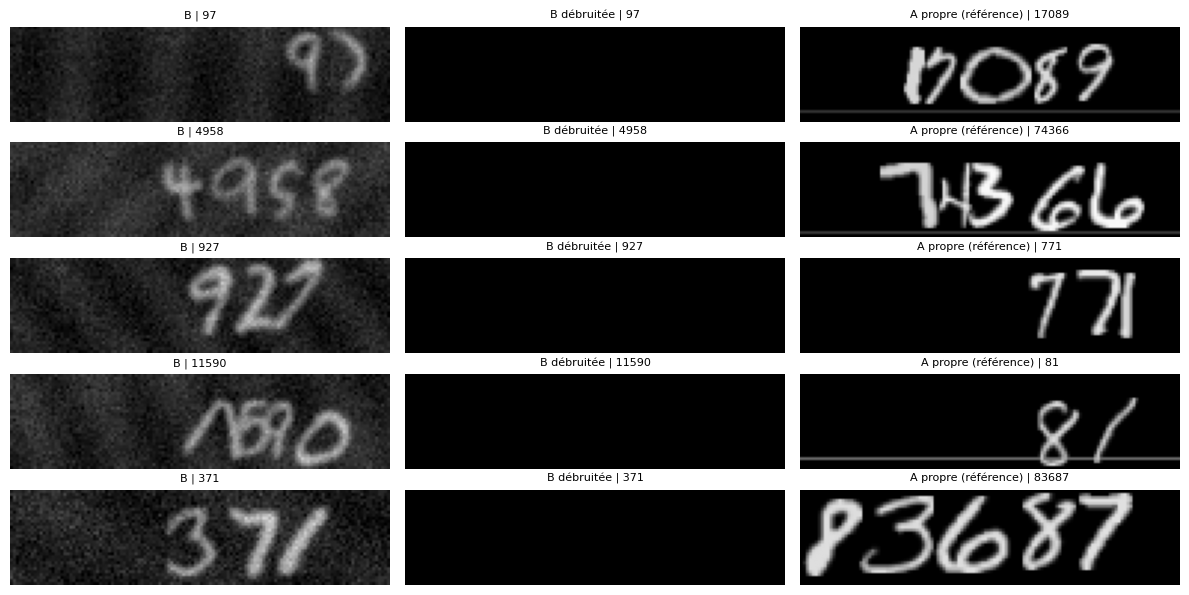

échec journalisé


In [22]:
ae_v3 = keras.models.load_model("debruiteur_v3.keras", compile=False)
XB_v3 = ae_v3.predict(XB["val"], batch_size=256, verbose=0)
XA_v3 = ae_v3.predict(Xc_val, batch_size=256, verbose=0)

ex_b0 = lire_et_afficher("B val, sans débruitage", XB["val"], B)
ex_b1 = lire_et_afficher("B val, avec débruitage", XB_v3, B)
ex_a0 = lire_et_afficher("A val corrompue, sans débruitage", Xc_val, A)
ex_a1 = lire_et_afficher("A val corrompue, avec débruitage", XA_v3, A)

fig, axes = plt.subplots(5, 3, figsize=(12, 6))
for r in range(5):
    for c, (nom, X) in enumerate([("B", XB["val"]), ("B débruitée", XB_v3), ("A propre (référence)", XA["val"])]):
        axes[r, c].imshow(X[r, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(f"{nom} | {B['montant_val'][r] if c < 2 else A['montant_val'][r]}", fontsize=8)
plt.tight_layout(); plt.show()

journaliser_une_fois(2, "debruiteur_v3_effondre", corruption="v3", sortie="sigmoid", loss="mse", lr=1e-3,
                     mse_val=0.07138, exact_B_val_debruite=ex_b1,
                     remarque="sortie toute noire : MSE = celui d'une image nulle (E[x^2] de A propre = 0.0713)")
print("échec journalisé")

**Version 4.** Trois corrections : sortie linéaire (l'image est ramenée dans [0, 1] avec `clip` ensuite), perte MSE pondérée où les pixels d'encre comptent 10 fois plus (pour que « tout noir » ne soit plus une bonne réponse), taux d'apprentissage 5e-4. Un garde-fou arrête l'entraînement si la sortie devient constante.

La corruption est lente : la première époque de l'essai v3, qui corrompait tout le train à chaque époque, a duré 72 s. L'entraînement utilise donc 3 jeux de corruptions précalculés une fois (86 s en tout), repris à tour de rôle d'une époque à l'autre. Le modèle gardé est celui de la dernière époque ; la lecture de B affichée pendant l'entraînement sert d'information, jamais de critère de sélection.

In [ ]:
def perte_ponderee(y_true, y_pred):
    w = 1.0 + 9.0 * y_true
    return tf.reduce_mean(w * tf.square(y_true - y_pred))

def build_ae(nom="debruiteur", lr=5e-4):
    inp = keras.Input(shape=(IMG_H, IMG_W, 1))
    c1 = layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    c1 = layers.Conv2D(32, 3, padding="same", activation="relu")(c1)
    p1 = layers.MaxPooling2D(2)(c1)
    c2 = layers.Conv2D(64, 3, padding="same", activation="relu")(p1)
    c2 = layers.Conv2D(64, 3, padding="same", activation="relu")(c2)
    p2 = layers.MaxPooling2D(2)(c2)
    b = layers.Conv2D(128, 3, padding="same", activation="relu")(p2)
    d2 = layers.Concatenate()([layers.UpSampling2D(2)(b), c2])
    d2 = layers.Conv2D(64, 3, padding="same", activation="relu")(d2)
    d1 = layers.Concatenate()([layers.UpSampling2D(2)(d2), c1])
    d1 = layers.Conv2D(32, 3, padding="same", activation="relu")(d1)
    out = layers.Conv2D(1, 1, activation="linear")(d1)          # sortie linéaire : pas de saturation
    m = keras.Model(inp, out, name=nom)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=perte_ponderee)
    return m

def debruiter(ae, X):
    return np.clip(ae.predict(X, batch_size=256, verbose=0), 0.0, 1.0)

In [ ]:
def entrainer_ae(nom, epochs=30, batch=64, seed=SEED, lr=5e-4):
    keras.utils.set_random_seed(seed)
    t0 = time.time()
    rng_pre = np.random.default_rng(seed)
    COPIES = [corrompre(XA["train"], rng_pre) for _ in range(3)]
    Xc_v = corrompre(XA["val"], np.random.default_rng(123))      # validation corrompue, fixe
    print(f"corruptions précalculées en {time.time() - t0:.0f} s")
    ae = build_ae(nom, lr)
    hist = {"loss_tr": [], "loss_va": [], "exact_B": []}
    t0 = time.time()
    for e in range(epochs):
        h = ae.fit(COPIES[e % len(COPIES)], XA["train"], validation_data=(Xc_v, XA["val"]),
                   epochs=1, batch_size=batch, verbose=0)
        hist["loss_tr"].append(h.history["loss"][0]); hist["loss_va"].append(h.history["val_loss"][0])
        if e < 5:                                                   # garde-fou anti-effondrement
            s = float(debruiter(ae, XB["val"][:200]).std())
            print(f"  époque {e+1} | perte val {hist['loss_va'][-1]:.5f} | écart-type de la sortie {s:.4f}")
            if s < 0.01:
                print("EFFONDREMENT : sortie constante, arrêt."); break
        if (e + 1) % 5 == 0:
            lus, _ = lire_probs(predire_probs(cnn_final, debruiter(ae, XB["val"])))
            hist["exact_B"].append(float(np.mean(lus == B["montant_val"])))
            print(f"  époque {e+1:3d} | perte val {hist['loss_va'][-1]:.5f} | "
                  f"CNN lit B val débruitée : {hist['exact_B'][-1]:.3f}")
    journaliser(2, nom, epochs=e + 1, batch=batch, seed=seed, corruption="v3", sortie="lineaire",
                loss="mse ponderee (1+9*ink)", lr=lr, perte_val=hist["loss_va"][-1],
                exact_B_val_debruite=hist["exact_B"][-1] if hist["exact_B"] else None,
                nb_params=int(ae.count_params()), duree_s=round(time.time() - t0))
    return ae, hist

In [23]:
if os.path.exists("debruiteur_v4.keras"):
    ae = keras.models.load_model("debruiteur_v4.keras", compile=False)
    H_ae = lire_histoire("ae")
else:
    ae, H_ae = entrainer_ae("debruiteur_v4")
    ae.save("debruiteur_v4.keras")
    sauver_histoire("ae", H_ae)

corruptions précalculées en 86 s
  époque 1 | perte val 0.03800 | écart-type de la sortie 0.2487
  époque 2 | perte val 0.03545 | écart-type de la sortie 0.2439
  époque 3 | perte val 0.03494 | écart-type de la sortie 0.2451
  époque 4 | perte val 0.03413 | écart-type de la sortie 0.2444
  époque 5 | perte val 0.03350 | écart-type de la sortie 0.2457
  époque   5 | perte val 0.03350 | CNN lit B val débruitée : 0.662
  époque  10 | perte val 0.03264 | CNN lit B val débruitée : 0.665
  époque  15 | perte val 0.03178 | CNN lit B val débruitée : 0.662
  époque  20 | perte val 0.03130 | CNN lit B val débruitée : 0.665
  époque  25 | perte val 0.03101 | CNN lit B val débruitée : 0.662
  époque  30 | perte val 0.03085 | CNN lit B val débruitée : 0.672


La mesure demandée par le sujet : lire les images de validation de B avec et sans débruitage. On ajoute A corrompue, qui donne un point de comparaison sur 3 000 images.

B val, sans débruitage               exact = 0.0025 | par longueur : {1: (0.0, 18), 2: (0.0, 54), 3: (0.0, 150), 4: (0.0, 120), 5: (0.017, 58)}
B val, avec débruitage               exact = 0.6725 | par longueur : {1: (1.0, 18), 2: (0.907, 54), 3: (0.787, 150), 4: (0.608, 120), 5: (0.19, 58)}
A val corrompue, sans débruitage     exact = 0.0010 | par longueur : {1: (0.0, 137), 2: (0.0, 467), 3: (0.0, 985), 4: (0.0, 907), 5: (0.006, 504)}
A val corrompue, avec débruitage     exact = 0.6700 | par longueur : {1: (0.942, 137), 2: (0.869, 467), 3: (0.804, 985), 4: (0.589, 907), 5: (0.296, 504)}


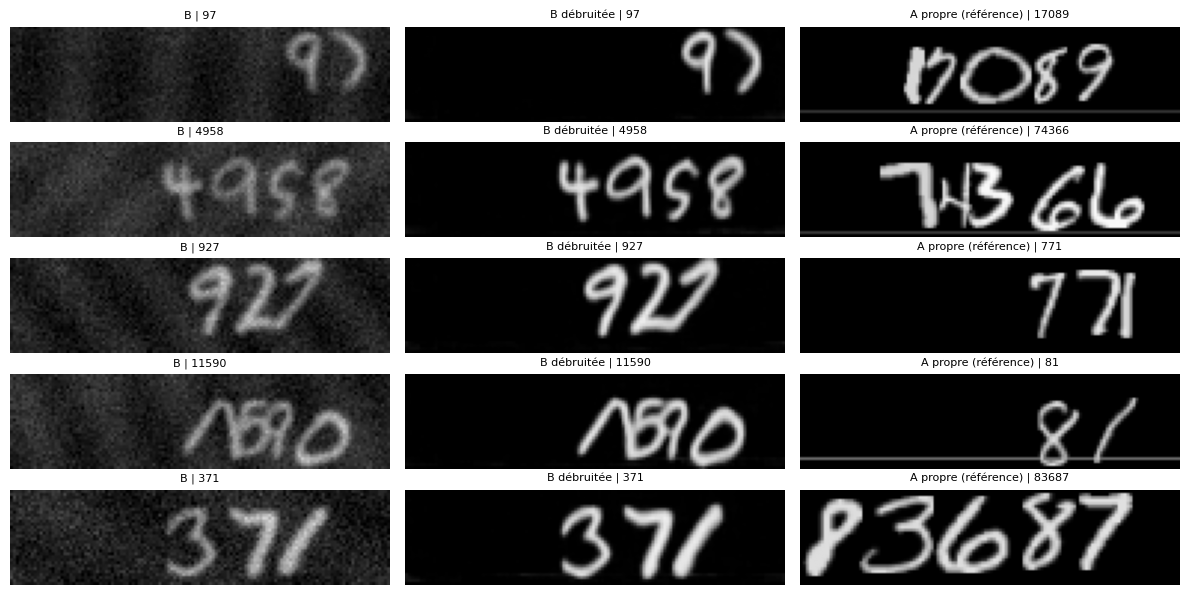

In [24]:
XB_den = debruiter(ae, XB["val"])
XA_den = debruiter(ae, Xc_val)

ex_b0 = lire_et_afficher("B val, sans débruitage", XB["val"], B)
ex_b1 = lire_et_afficher("B val, avec débruitage", XB_den, B)
ex_a0 = lire_et_afficher("A val corrompue, sans débruitage", Xc_val, A)
ex_a1 = lire_et_afficher("A val corrompue, avec débruitage", XA_den, A)
journaliser_une_fois(2, "lecture_B_val_v4", sans_debruitage=ex_b0, avec_debruitage=ex_b1,
            A_corrompue_sans=ex_a0, A_corrompue_avec=ex_a1)

fig, axes = plt.subplots(5, 3, figsize=(12, 6))
for r in range(5):
    for c, (nom, X) in enumerate([("B", XB["val"]), ("B débruitée", XB_den), ("A propre (référence)", XA["val"])]):
        axes[r, c].imshow(X[r, :, :, 0], cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(f"{nom} | {B['montant_val'][r] if c < 2 else A['montant_val'][r]}", fontsize=8)
plt.tight_layout(); plt.show()

**Lecture.**
- Lecture de B en validation : 0,0025 sans débruitage, **0,6725** avec. Sur A corrompue : 0,001 puis 0,670. Les deux valeurs débruitées sont presque égales : la corruption simulée se transfère bien au vrai scanner B.
- Le gain est présent à toutes les longueurs (1 chiffre : 1,000 ; 5 chiffres : 0,190 sur B). Avec 400 images, l'incertitude sur 0,6725 est d'environ ±0,024.
- La lecture de B pendant l'entraînement est restée entre 0,662 et 0,672 de l'époque 5 à l'époque 30, alors que la perte baissait encore : on ne peut pas dire que les dernières époques aident.
- Les images débruitées ressemblent à des chiffres de A (traits un peu plus épais et lisses).

## 10. Évaluation finale sur le test

On fige les trois modèles : CNN final, détecteur avec son seuil de coût fixé sur la validation (0,0163) et auto-encodeur v4. Le test est évalué une seule fois : la cellule refuse de se relancer dans la même session. Rien n'est modifié après avoir vu ces chiffres.

In [25]:
if "TEST_DONE" in globals():
    raise RuntimeError("Le test a déjà été évalué dans cette session : ne pas relancer.")
TEST_DONE = True

SEUIL_DET = float(seuils[ic])      # fixé sur la validation (coût d'une fraude manquée = 50 revues)
def se(p, n): return float(np.sqrt(p * (1 - p) / n))

# 1) Lecteur sur A test
pt = predire_probs(cnn_final, XA["test"]); lus_t, _ = lire_probs(pt)
ex_t = float(np.mean(lus_t == A["montant_test"]))
base_t = [float(np.bincount(Y_test[:, k], minlength=N_CLASSES).max() / len(Y_test)) for k in range(L_MAX)]
print(f"[A test] montant exact = {ex_t:.4f} ± {se(ex_t, len(lus_t)):.4f}  (cible 0.85)")
print("  par position      :", [round(a, 3) for a in exactitude_par_position(pt, Y_test)])
print("  réponse constante :", [round(b, 3) for b in base_t])
print("  par longueur      :", {n: (round(v[0], 3), v[1]) for n, v in exactitude_par_longueur(lus_t, A["montant_test"]).items()})

# 2) Détecteur sur A test
s_te = det.predict(XA["test"], batch_size=512, verbose=0).ravel()
y_te = ALT["test"]; typ_te = A["type_test"]
auc_te = float(roc_auc_score(y_te, s_te))
fpr_t, tpr_t, _ = roc_curve(y_te, s_te)
i5t = np.where(fpr_t <= 0.05)[0].max()
print(f"\n[A test] AUC = {auc_te:.4f} (cible 0.95) | rappel à 5 % de fausses alertes (ROC du test) = {tpr_t[i5t]:.3f}")
for nom, seuil in [("seuil 5 % fixé sur val", seuil5), ("seuil de coût fixé sur val", SEUIL_DET)]:
    al = s_te >= seuil
    print(f"  {nom} ({seuil:.4f}) : fausses alertes = {al[typ_te == 0].mean():.3f} | rappel global = {al[y_te == 1].mean():.3f}")
    for t in (1, 2):
        sel = typ_te == t
        print(f"     type {t} : rappel = {al[sel].mean():.3f} | manqués = {int((~al[sel]).sum())}/{int(sel.sum())}")

# 3) Lecteur sur B test, sans et avec débruitage
XB_te_den = debruiter(ae, XB["test"])
res_b = {}
for nom, X in [("sans débruitage", XB["test"]), ("avec débruitage", XB_te_den)]:
    lus, _ = lire_probs(predire_probs(cnn_final, X))
    ex = float(np.mean(lus == B["montant_test"])); res_b[nom] = ex
    print(f"\n[B test, {nom}] montant exact = {ex:.4f} ± {se(ex, len(lus)):.4f}  (cible 0.70)")
    print("  par longueur :", {n: (round(v[0], 3), v[1]) for n, v in exactitude_par_longueur(lus, B["montant_test"]).items()})

journaliser_une_fois(2, "TEST_final", A_exact=ex_t, A_auc=auc_te, A_rappel_5pct=float(tpr_t[i5t]),
            seuil_det=SEUIL_DET, B_sans=res_b["sans débruitage"], B_avec=res_b["avec débruitage"])
print("\ncibles : A 0.85 | AUC 0.95 | B 0.70")

[A test] montant exact = 0.6988 ± 0.0065  (cible 0.85)
  par position      : [0.963, 0.908, 0.86, 0.888, 0.954]
  réponse constante : [0.107, 0.101, 0.186, 0.526, 0.827]
  par longueur      : {1: (0.969, 224), 2: (0.926, 706), 3: (0.84, 1702), 4: (0.615, 1504), 5: (0.31, 864)}

[A test] AUC = 0.9996 (cible 0.95) | rappel à 5 % de fausses alertes (ROC du test) = 0.998
  seuil 5 % fixé sur val (0.0028) : fausses alertes = 0.051 | rappel global = 0.998
     type 1 : rappel = 1.000 | manqués = 0/214
     type 2 : rappel = 0.996 | manqués = 1/281
  seuil de coût fixé sur val (0.0163) : fausses alertes = 0.022 | rappel global = 0.996
     type 1 : rappel = 1.000 | manqués = 0/214
     type 2 : rappel = 0.993 | manqués = 2/281

[B test, sans débruitage] montant exact = 0.0010 ± 0.0006  (cible 0.70)
  par longueur : {1: (0.0, 148), 2: (0.0, 403), 3: (0.0, 1007), 4: (0.001, 931), 5: (0.004, 511)}

[B test, avec débruitage] montant exact = 0.6333 ± 0.0088  (cible 0.70)
  par longueur : {1: (0.93

| Exigence | Résultat (test) | Cible | Verdict |
|---|---|---|---|
| Montant exact, scanner A | 0,699 ± 0,007 | 0,85 | en dessous de 0,151 |
| AUC des altérations, scanner A | 0,9996 | 0,95 | atteinte |
| Montant exact, scanner B avec débruitage | 0,633 ± 0,009 | 0,70 | en dessous de 0,067 |

- **Montant sur A.** Le test (0,699) est plus bas que la validation (0,757), qui avait servi à choisir l'architecture et la durée d'entraînement : le chiffre du test est le chiffre honnête. L'écart à la cible vient des montants de 4 et 5 chiffres (0,615 et 0,310), qui forment 47 % du test.
- **Détecteur.** Les seuils fixés sur la validation se transfèrent bien : 2,2 % de fausses alertes et rappel 0,996 au seuil de coût, 5,1 % et 0,998 au seuil à 5 %. Il n'y a que 1 à 2 altérations manquées, donc rien à conclure sur la difficulté relative des types.
- **Montant sur B.** 0,001 sans débruitage, 0,633 avec. La cible de 0,70 est à peu près ce que notre lecteur obtient sur A propre (0,699) : tant que le lecteur lui-même ne progresse pas, il y a peu de chances que B dépasse ce niveau.

## 11. Problèmes rencontrés et améliorations

- **Le MLP ne convient pas à la tâche.** Un poids par pixel oblige à réapprendre chaque chiffre à chaque endroit : 0,135 en validation. Le CNN, grâce au partage des poids, passe à 0,757 avec 10 fois moins de paramètres.
- **Un champ réceptif trop petit limite le CNN.** Le calcul à la main donne 22 px pour la base, juste la hauteur d'un chiffre ; passer à 46 px (4 blocs) ou 36 px (noyau 5) fait gagner environ 0,14.
- **Le CNN n'avait pas fini d'apprendre.** À 30 époques la validation est à 0,642, à 80 époques à 0,757.
- **Les scores varient d'une graine à l'autre** (±0,03). D'où l'étude à 3 graines, la moyenne des 5 dernières époques et une règle de choix écrite dans le code plutôt qu'un choix à l'œil.
- **L'agrégation compte.** Avec GAP, la position est perdue et le modèle n'apprend rien (0,069) : le flatten est indispensable pour une lecture par positions.
- **L'auto-encodeur s'est effondré** (v3 : images noires, B à 0,010). Sortie linéaire, perte pondérée sur l'encre, taux d'apprentissage réduit et garde-fou ont donné la v4 : B passe de 0,0025 à 0,6725.
- **La corruption a demandé trois versions**, chacune comparée aux statistiques de B (fond, encre, contraste, netteté, grain).
- **Pistes non testées pour combler les écarts :** entraînement plus long, plus d'augmentation, plusieurs modèles moyennés, et affinage du lecteur avec les 600 images étiquetées de B.

## 12. Page de décisions

**Protocole.** Tous les réglages sont faits sur la validation. Le test n'a été évalué qu'une seule fois, à la fin, sur les modèles figés. Graine 0. Versions : Python 3.13.15, TensorFlow 2.21.0, scikit-learn 1.6.1, NumPy 2.1.3.. Toutes les expériences, échecs compris, sont dans `journal.jsonl` (jalon=2).

### 1. Résultats sur le test, comparés aux cibles

| Exigence | Résultat (test) | Cible | Écart |
|---|---|---|---|
| Montant exact, scanner A | **0,699 ± 0,007** | ≥ 0,85 | −0,151 |
| Altérations, AUC, scanner A | **0,9996** | ≥ 0,95 | atteinte |
| Montant exact, scanner B (avec débruitage) | **0,633 ± 0,009** | ≥ 0,70 | −0,067 |
| Montant exact, scanner B (sans débruitage) | 0,001 | | |

Comparaison avec le MLP du jalon 1 (validation) : 0,135 contre 0,757 pour le CNN final, avec 231 k paramètres contre 2,27 M.

Détail du CNN sur A (test) :

| Position | unités | dizaines | centaines | milliers | dizaines de milliers |
|---|---|---|---|---|---|
| CNN | 0,963 | 0,908 | 0,860 | 0,888 | 0,954 |
| Réponse constante | 0,107 | 0,101 | 0,186 | 0,526 | 0,827 |

| Longueur | 1 chiffre | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Exact | 0,969 | 0,926 | 0,840 | 0,615 | 0,310 |

### 2. Vérification théorique (3 blocs 32, 64, 64 ; dense 128 ; 5 têtes de 11 classes)

| Couche | Sortie | Paramètres |
|---|---|---|
| Conv 3×3 (32) | 32×128×32 | 3·3·1·32 + 32 = 320 |
| Pool 2×2 | 16×64×32 | 0 |
| Conv 3×3 (64) | 16×64×64 | 18 496 |
| Pool 2×2 | 8×32×64 | 0 |
| Conv 3×3 (64) | 8×32×64 | 36 928 |
| Pool 2×2 | 4×16×64 | 0 |
| Flatten | 4 096 | 0 |
| Dense 128 | 128 | 4 096·128 + 128 = 524 416 |
| 5 têtes | 5×11 | 5·(128·11 + 11) = 7 095 |
| **Total** | | **587 255** (identique à `summary()`) |

**Champ réceptif.** Chaque convolution 3×3 ajoute 2 fois le « saut », chaque pooling ajoute 1 fois le saut puis le double. On obtient 3, 4, 8, 10, 18, puis **22 px**. Un neurone de la dernière carte voit un carré de 22×22 pixels, ce qui est proche de la hauteur d'un chiffre (18 à 26 px) : il voit à peu près un chiffre, mais pas toujours en entier. Avec 4 blocs, le champ passe à 46 px.

### 3. Étude de conception (30 époques, validation, moyenne des 5 dernières époques)

| Variante | Paramètres | Champ | Exact val (moy ± écart-type, 3 graines) | Écart train − val |
|---|---|---|---|---|
| 2 blocs | 2 123 191 | 10 px | 0,353 (1 graine) | 0,246 |
| Base (3 blocs, noyau 3, max-pool) | 587 255 | 22 px | 0,508 ± 0,013 | 0,204 |
| Pooling moyen | 587 255 | 22 px | 0,448 ± 0,028 | 0,156 |
| GAP au lieu de flatten | 71 159 | 22 px | 0,069 (1 graine) | −0,007 |
| Noyau 5 | 686 071 | 36 px | 0,650 ± 0,031 | 0,211 |
| **4 blocs** | **230 967** | **46 px** | **0,645 ± 0,032** | **0,108** |

**Lecture.**
- Un champ réceptif plus grand donne de meilleurs résultats (10 px : 0,35 ; 22 px : 0,51 ; 36 à 46 px : 0,65). Les deux façons de l'agrandir (4 blocs, noyau 5) gagnent environ 0,14, bien au-dessus du bruit entre graines.
- Le nombre de paramètres n'explique pas l'écart : 2 blocs a le plus de paramètres et le pire score, tandis que 4 blocs en a 231 k et égale noyau 5 (686 k).
- Cette étude est cohérente avec un effet du champ réceptif, sans le prouver : passer à 4 blocs change aussi la profondeur et la taille du flatten.
- Le pooling max fait mieux que le pooling moyen (0,508 contre 0,448), mais l'écart repose sur 3 graines. L'explication possible (le max conserve la réponse la plus forte à un trait fin) n'a pas été testée.
- Noyau 5 et 4 blocs sont à égalité (0,005 d'écart pour un écart-type de 0,03).

**Règle de choix.** On prend la meilleure moyenne (noyau 5), on garde les variantes à moins d'un écart-type d'elle (noyau 5 et 4 blocs), puis celle qui a le moins de paramètres : **4 blocs**. C'est aussi celle qui sur-apprend le moins (écart 0,108). Modèle final : 80 époques, décalage ±4 px, dropout 0,3 (même budget que le MLP). Validation 0,757, test 0,699.

### 4. Rôle de la couche dense dans la lecture par positions

Les convolutions détectent des motifs locaux sans savoir où ils se trouvent. Après le flatten, la couche dense reçoit toute la carte de caractéristiques, position comprise. Chaque tête, qui est une simple couche softmax sur ces 128 valeurs, peut alors se spécialiser dans sa position.

Preuve : en remplaçant le flatten par une moyenne globale (GAP), qui supprime l'information de position, le modèle n'apprend même pas l'entraînement (exact train 0,062, val 0,069, contre 0,508 avec flatten). Ce n'est pas du sur-apprentissage mais un sous-apprentissage : sans position, la tête des unités ne peut pas distinguer les unités des dizaines.

### 5. Seuil d'alerte du détecteur d'altération

Le détecteur est un CNN binaire (4 blocs, sortie sigmoïde, poids de classe pour environ 10 % de positifs). Il donne à chaque chèque un score ; au-dessus du seuil, le chèque part vers un opérateur.

**Hypothèse de coûts (à justifier, non fournie par l'énoncé).** Une fausse alerte coûte 1 unité (quelques minutes d'opérateur). Une fraude manquée coûte 50 unités (montant détourné et frais de traitement, 50 fois une revue). On minimise 1 × FP + 50 × FN sur la validation.

| Rapport de coûts | Seuil | Fausses alertes | Rappel | Fraudes manquées (val, sur 285) |
|---|---|---|---|---|
| 5 à 10 | 0,503 | 0,3 % | 0,989 | 3 |
| **50 (retenu)** | **0,0163** | **1,9 %** | **0,993** | **2** |
| 200 et plus | 0,0007 | 8,4 % | 1,000 | 0 |

Les seuils sont bas parce que les scores sont très tranchés (les chèques normaux sont proches de 0). Avec les poids de classe, ce ne sont pas des probabilités calibrées.

**Résultat sur le test, seuil fixé sur la validation :** 2,2 % de fausses alertes, rappel 0,996, 2 fraudes manquées sur 495 (type 1 : 0 sur 214 ; type 2 : 2 sur 281). Avec un seuil à 5 % de fausses alertes (0,0028) : 5,1 % de fausses alertes, rappel 0,998, 1 manquée. Les seuils se transfèrent bien de la validation au test.

**Le point à 5 %.** Sous l'hypothèse de 50 000 chèques par jour dont 10 % altérés (valeurs supposées), passer de 0,3 % à 4,5 % de fausses alertes ajoute environ 1 890 revues par jour pour environ 35 fraudes de plus détectées, soit environ 54 revues par fraude supplémentaire. Cela se justifie seulement si une fraude manquée coûte plus de 54 revues. Si les fraudes réelles sont bien plus rares que 10 %, les fausses alertes deviennent relativement plus coûteuses et le seuil retenu devrait monter.

**Types d'altération.** Le type 1 correspond probablement à un chiffre ajouté en tête et le type 2 à un chiffre retouché (lecture visuelle, non confirmée). Avec 1 à 2 fraudes manquées, on ne peut pas dire qu'un type est plus difficile.

### 6. Débruitage et scanner B

Les images du scanner B sont plus pâles (fond autour de 0,18, encre autour de 0,78), floues, striées et granuleuses. Le lecteur entraîné sur A lit presque rien sur B (0,001). On corrompt les images de A pour imiter B (rotation, flou, fond relevé, contraste réduit, raies, taches, grain), avec des statistiques calées sur les images de B, sans utiliser ses étiquettes. Un auto-encodeur débruiteur apprend à restituer l'image propre.

La première version (sortie sigmoïde, perte MSE) s'est effondrée en images noires : sa perte était celle d'une image nulle (0,0714). La version finale utilise une sortie linéaire, une perte pondérée sur l'encre et un taux d'apprentissage de 5e-4. Le modèle retenu est celui de la dernière époque, sans sélection sur B.

| Lecture de B | Sans débruitage | Avec débruitage |
|---|---|---|
| Validation (400 images) | 0,0025 | 0,6725 |
| Test (3 000 images) | 0,001 | 0,633 |

### 7. Explication des écarts aux cibles

- **Montant sur A (0,699 contre 0,85).** Les montants de 4 et 5 chiffres représentent 47 % du test et sont lus à 0,615 et 0,310 : les erreurs de plusieurs têtes s'additionnent. Le modèle n'avait pas convergé (validation encore en hausse à l'époque 80), et le test est plus bas que la validation (0,757) parce que la validation a servi à choisir l'architecture. Ce sont des hypothèses non testées : entraînement plus long, plus d'augmentation, ensemble de modèles.
- **Montant sur B (0,633 contre 0,70).** Notre lecteur plafonne à 0,699 sur A propre, donc la cible de 0,70 sur B est à peu près le niveau du lecteur sur A propre. L'écart de 0,066 entre B débruité et A propre mesure ce que perdent la simulation et le nettoyage. Pour atteindre 0,70 sur B, il faudrait d'abord améliorer le lecteur lui-même.
- **Piste non testée :** les 600 images étiquetées de B (entraînement) n'ont pas été utilisées. Elles pourraient servir à affiner le lecteur.
- **Limites.** Les modèles finaux viennent d'une seule graine. Les résultats GPU ne sont pas identiques d'une exécution à l'autre (la base est passée de 0,606 à 0,587 entre deux exécutions).

## 13. Fichiers produits

Résultats du test, liste des fichiers du dossier et vérification du journal.

In [26]:
import os, json

assert "TEST_DONE" in globals(), "Les variables du test n'existent plus dans cette session."
resultats_test = {
    "A_montant_exact": ex_t, "A_auc": auc_te, "A_rappel_5pct_roc_test": float(tpr_t[i5t]),
    "seuil_detecteur_cout": SEUIL_DET, "seuil_5pct": float(seuil5),
    "B_test_sans_debruitage": res_b["sans débruitage"], "B_test_avec_debruitage": res_b["avec débruitage"],
}
json.dump(resultats_test, open("resultats_test_jalon2.json", "w"), indent=2)

print("dossier :", os.getcwd(), "\n")
for f in sorted(os.listdir(".")):
    print(f"{f:32s}{os.path.getsize(f) / 1e6:9.1f} MB")

lignes = [json.loads(l) for l in open("journal.jsonl")]
print("\njournal :", len(lignes), "entrées | TEST_final présent :", any(l["nom"] == "TEST_final" for l in lignes))

dossier : /content/drive/MyDrive/uc1_jalon2 

cnn_final_80ep.keras                  2.9 MB
debruiteur_v3.keras                   3.4 MB
debruiteur_v4.keras                   3.4 MB
detecteur_blocs4.keras                2.7 MB
histories_jalon2.json                 0.0 MB
journal.jsonl                         0.0 MB
mlp_base_80ep.keras                  27.3 MB
notes_jalon2.json                     0.0 MB
resultats_design.json                 0.0 MB
resultats_test_jalon2.json            0.0 MB
uc1_domaineA.npz                     20.6 MB
uc1_domaineB.npz                     14.1 MB

journal : 25 entrées | TEST_final présent : True


## Journal du jalon 2

Source brute : `journal.jsonl` (25 entrées horodatées, non modifiées). Le tableau ci-dessous le résume par étape. Toutes les valeurs de A à D sont mesurées sur la **validation** ; le test n'apparaît qu'en E, une seule fois.

### A. Étude de conception (30 époques, 3 graines sauf mention)

| Variante | Paramètres | Exact val. (moy. des 5 dernières époques, moy. sur graines) | Conclusion |
|---|---|---|---|
| 3 blocs, max-pool, flatten (base) | 587 255 | 0,508 | Point de départ |
| 3 blocs, avg-pool | 587 255 | 0,448 | Moins bon que max-pool : le max garde les traits marqués |
| **4 blocs** | **230 967** | **0,645** | Retenu : meilleur compromis score / paramètres |
| 3 blocs, noyau 5 | 686 071 | 0,650 | Équivalent à 4 blocs (écart < écart-type) mais 3 fois plus de paramètres |
| 2 blocs (1 graine) | 2 123 191 | 0,353 | Trop de paramètres dans le dense, champ réceptif trop petit |
| GAP à la place de flatten (1 graine) | 71 159 | 0,069 | **Échec** : GAP supprime la position, or chaque tête lit une position précise |

### B. CNN final et référence MLP (80 époques, graine 0)

| Modèle | Paramètres | Exact val. | Durée |
|---|---|---|---|
| **CNN 4 blocs** | 230 967 | **0,757** | 370 s |
| MLP 512-256-128 | 2 268 983 | 0,135 | 208 s |

Le CNN fait mieux avec 10 fois moins de paramètres : le partage des poids exploite la structure de l'image, ce que le MLP ne fait pas.

### C. Détecteur d'altération

| Modèle | Paramètres | AUC val. | Remarque |
|---|---|---|---|
| CNN binaire 4 blocs | 224 001 | 0,9994 | Meilleure époque retenue : 37 sur 40 |

### D. Scanner B : corruption et débruiteur

| Étape | Résultat | Décision |
|---|---|---|
| Corruption v2 | Lecture de B : 0,0025 ; A corrompue : 0,0007 | Écartée : grain trop net, encre trop pâle, fond trop clair |
| Corruption v3 | Fond 0,178, encre p99 0,768, A corrompue : 0,001 | Retenue pour l'entraînement |
| Débruiteur v3 (sortie sigmoïde, MSE, lr 1e-3) | MSE val. 0,0714 ; lecture de B : 0,010 | **Échec** : sorties toutes noires |
| Diagnostic | 0,0713 = E[x²] de A propre | Le modèle prédit une image nulle, c'est le minimum trivial |
| Débruiteur v4 (sortie linéaire, MSE pondérée 1+9·encre, lr 5e-4, garde anti-effondrement) | Perte val. 0,0308 ; **lecture de B : 0,0025 → 0,6725** | Retenu |

### E. Test, utilisé une seule fois (9 octobre)

| Mesure | Résultat | Objectif |
|---|---|---|
| Montant exact, scanner A | 0,699 | 0,85 (non atteint) |
| AUC du détecteur | 0,9996 | 0,95 (atteint) |
| Rappel à 5 % de fausses alertes | 0,998 | - |
| Seuil retenu (coût C_MISS = 50 · C_FA) | 0,0163 | Justification dans la page de décisions |
| Scanner B sans débruitage | 0,001 | - |
| Scanner B avec débruitage | 0,633 | 0,70 (non atteint) |